In [1]:
!pip install --quiet MDAnalysis matplotlib seaborn numpy


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 3.0 MB/s eta 0:00:00


In [10]:
# Installazione rapida di GROMACS su Colab tramite condacolab
!pip install -q condacolab
import condacolab
condacolab.install()



📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:08
🔁 Restarting kernel...


In [1]:
# Installa gromacs e gli strumenti di plot
!mamba install -y -c conda-forge gromacs mdanalysis matplotlib seaborn

# Converti il primo frame del .tpr in un file .gro per avere una topologia compatibile al 100% con Python
!gmx editconf -f step7_production.tpr -o step7_topology.gro

[+] 0.0s
[+] 0.0s
[+] 0.1s
conda-forge/linux-64  ⣾  
conda-forge/noarch    ⣾  [+] 0.2s
conda-forge/linux-64   4%
conda-forge/noarch     6%[+] 0.3s
conda-forge/linux-64  11%
conda-forge/noarch    21%[+] 0.4s
conda-forge/linux-64  18%
conda-forge/noarch    34%[+] 0.5s
conda-forge/linux-64  22%
conda-forge/noarch    39%[+] 0.6s
conda-forge/linux-64  25%
conda-forge/noarch    45%[+] 0.7s
conda-forge/linux-64  30%
conda-forge/noarch    56%[+] 0.8s
conda-forge/linux-64  33%
conda-forge/noarch    62%[+] 0.9s
conda-forge/linux-64  36%
conda-forge/noarch    73%[+] 1.0s
conda-forge/linux-64  42%
conda-forge/noarch    85%[+] 1.1s
conda-forge/linux-64  46%
conda-forge/noarch    92%[+] 1.2s
conda-forge/linux-64  48%
conda-forge/noarch    97%conda-forge/noarch                                
[+] 1.3s
conda-forge/linux-64  56%[+] 1.4s
conda-forge/linux-64  60%[+] 1.5s
conda-forge/linux-64  68%[+] 1.6s
conda-forge/linux-64  76%[+] 1.7s
conda-forge/linux-64  80%[+] 1.8s
conda-forge/linux-64  84%[+] 1.9

In [2]:
# Download diretto dei file da Dropbox (parametro dl=1)
!wget -O step7_centered.xtc "https://www.dropbox.com/scl/fi/a889tukrivoo0ayhp14xl/step7_centered.xtc?rlkey=mf92992ggast8zoqw3qlwhk1w&st=q9lnnv77&dl=1"
!wget -O step7_production.tpr "https://www.dropbox.com/scl/fi/ob63vf8gjijai7tdumlmq/step7_production.tpr?rlkey=uixtkvyfusa7yakujllbx2xqb&st=utn5ko6o&dl=1"

# Verifica delle dimensioni dei file scaricati
!ls -lh step7_centered.xtc step7_production.tpr

--2026-10-13 08:26:59--  https://www.dropbox.com/scl/fi/a889tukrivoo0ayhp14xl/step7_centered.xtc?rlkey=mf92992ggast8zoqw3qlwhk1w&st=q9lnnv77&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.3.18, 2620:100:6018:18::a27d:312
Connecting to www.dropbox.com (www.dropbox.com)|162.125.3.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc0b1d4db9c3816369874d65c9d3.dl.dropboxusercontent.com/cd/0/inline/DJ4jdFkyhZvosDrtUrs9trDod3B9_rxYHkfN1IO7aEiFlbBfMkJuKrehHai3fspz1Xr80IBAUMO9GqSV9ajPhJeDV8y2K7lb31wNfZuB5JHgth3DNh6vULpvupZBPbZriFU/file?dl=1# [following]
--2026-10-13 08:27:00--  https://uc0b1d4db9c3816369874d65c9d3.dl.dropboxusercontent.com/cd/0/inline/DJ4jdFkyhZvosDrtUrs9trDod3B9_rxYHkfN1IO7aEiFlbBfMkJuKrehHai3fspz1Xr80IBAUMO9GqSV9ajPhJeDV8y2K7lb31wNfZuB5JHgth3DNh6vULpvupZBPbZriFU/file?dl=1
Resolving uc0b1d4db9c3816369874d65c9d3.dl.dropboxusercontent.com (uc0b1d4db9c3816369874d65c9d3.dl.dropboxusercontent.com)... 162.125.83.15, 2620:100:6033:

Traiettoria caricata con successo: 5001 frame totali.


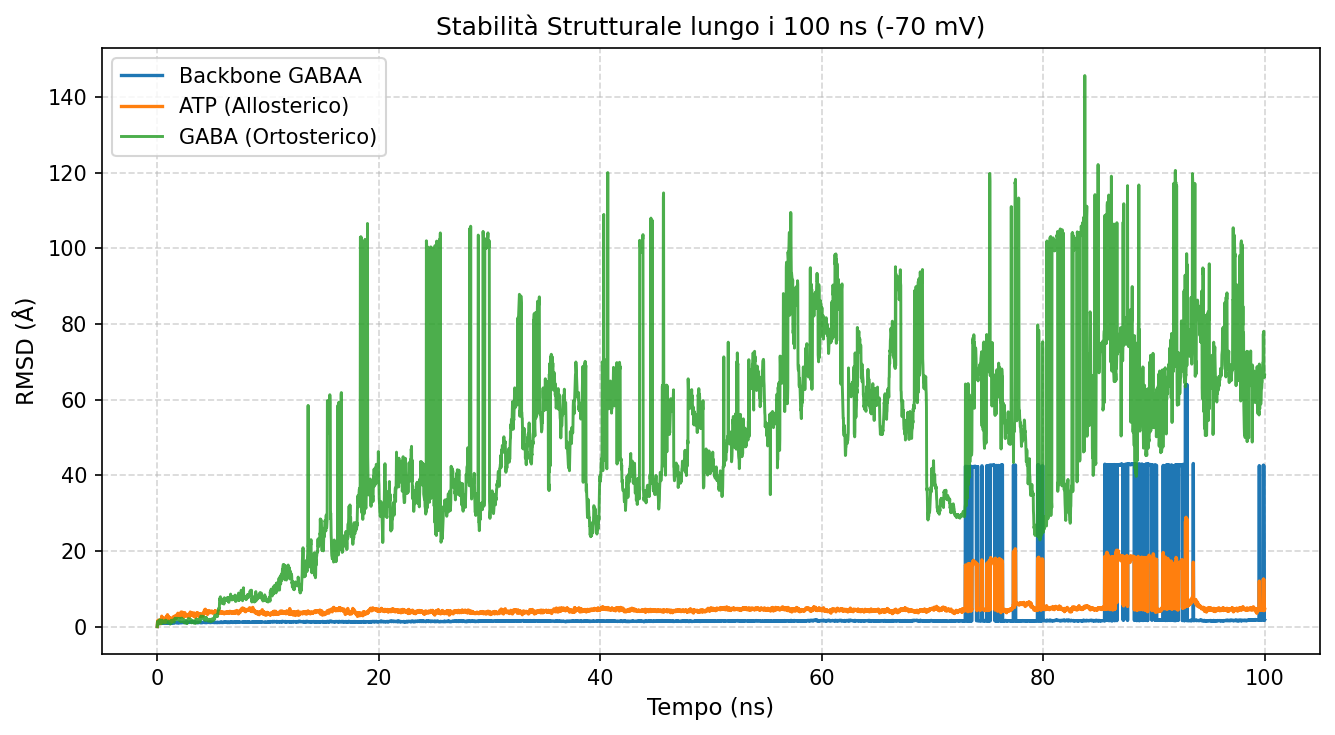

In [ ]:
import MDAnalysis as mda
from MDAnalysis.analysis import rms
import matplotlib.pyplot as plt

# Carica l'universo MD usando il file .gro generato da editconf
u = mda.Universe("step7_topology.gro", "step7_centered.xtc")
print(f"Traiettoria caricata con successo: {len(u.trajectory)} frame totali.")

# Calcolo RMSD per Backbone, ATP e GABA
R = rms.RMSD(u, u,
             select='backbone',
             groupselections=['resname ATP', 'resname GAB'],
             ref_frame=0)
R.run()

# Estrazione delle serie temporali
time_ns = R.results.rmsd[:, 1] / 1000.0  # da ps a ns
rmsd_backbone = R.results.rmsd[:, 2]     # Å
rmsd_atp = R.results.rmsd[:, 3]          # Å
rmsd_gaba = R.results.rmsd[:, 4]         # Å

# Generazione del grafico
plt.figure(figsize=(9, 5), dpi=150)
plt.plot(time_ns, rmsd_backbone, label='Backbone GABAA', color='#1f77b4', lw=1.6)
plt.plot(time_ns, rmsd_atp, label='ATP (Allosterico)', color='#ff7f0e', lw=1.6)
plt.plot(time_ns, rmsd_gaba, label='GABA (Ortosterico)', color='#2ca02c', lw=1.4, alpha=0.85)

plt.title("Stabilità Strutturale lungo i 100 ns (-70 mV)", fontsize=12)
plt.xlabel("Tempo (ns)", fontsize=11)
plt.ylabel("RMSD (Å)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig("rmsd_gabai_100ns.png", dpi=300)
plt.show()

In [2]:
import MDAnalysis as mda

# Carichiamo l'universo leggendo le coordinate del frame 0 da xtc
# (il formato PDB/GRO generato conterrà la corretta mappatura atomica per l'intera traiettoria)
!pip install --quiet MDAnalysis matplotlib seaborn numpy

import MDAnalysis as mda

# Generiamo un PDB di riferimento estraendo le coordinate iniziali
u_temp = mda.Universe("step7_centered.xtc")
u_temp.trajectory[0] # frame iniziale t=0
u_temp.atoms.write("reference_coords.gro")
print("✅ Coordinate iniziali salvate in reference_coords.gro")

/usr/local/lib/python3.13/site-packages/MDAnalysis/core/universe.py:1916: UserWarning: there is no reference attributes in this universe to guess types from
  warnings.warn(str(e))
/usr/local/lib/python3.13/site-packages/MDAnalysis/core/universe.py:1916: UserWarning: there is no reference attributes (elements, types, or names) in this universe to guess mass from
  warnings.warn(str(e))
/usr/local/lib/python3.13/site-packages/MDAnalysis/coordinates/GRO.py:444: UserWarning: Supplied AtomGroup was missing the following attributes: names, resnames, resids. These will be written with default values. Alternatively these can be supplied as keyword arguments.
  warnings.warn(


✅ Coordinate iniziali salvate in reference_coords.gro


In [3]:
# Installazione veloce di GROMACS in Colab via apt-get (richiede 15-20 secondi)
!apt-get update -qq && apt-get install -y -qq gromacs

# Estrazione della struttura e topologia completa a t=0 in formato .gro
!echo 0 | gmx trjconv -s step7_production.tpr -f step7_centered.xtc -dump 0 -o system_topology.gro

# Verifica del file generato
!ls -lh system_topology.gro
!head -n 5 system_topology.gro

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
               :-) GROMACS - gmx trjconv, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content
Command line:
  gmx trjconv -s step7_production.tpr -f step7_centered.xtc -dump 0 -o system_topology.gro

Note that major changes are planned in future for trjconv, to improve usability and utility.
Will write gro: Coordinate file in Gromos-87 format
Reading file step7_production.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file step7_production.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for output
Group     0 (         System) has 220792 elements
Group     1 (        Protein) has 27334 elements
Group     2 (      Protein-H) has 13658 elements
Group     3 (        C-alpha) has  1677 elements
Group     4 (       B

In [4]:
import MDAnalysis as mda

# Carichiamo la traiettoria con la topologia corretta
u = mda.Universe("system_topology.gro", "step7_centered.xtc")
print(f"✅ Universo MD caricato con successo! Frame totali: {len(u.trajectory)}")

# Individuazione dei ligandi
atp_res = u.select_atoms("resname ATP").residues
gab_res = u.select_atoms("resname GAB").residues

print(f"\nATP trovati ({len(atp_res)}):")
for r in atp_res:
    print(f"  ATP: resid {r.resid}, resname {r.resname}, atomi {len(r.atoms)}")

print(f"\nGABA trovati ({len(gab_res)}):")
for r in gab_res:
    print(f"  GABA: resid {r.resid}, resname {r.resname}, atomi {len(r.atoms)}")

✅ Universo MD caricato con successo! Frame totali: 5001

ATP trovati (1):
  ATP: resid 358, resname ATP, atomi 43

GABA trovati (2):
  GABA: resid 359, resname GAB, atomi 15
  GABA: resid 360, resname GAB, atomi 15


Calcolo delle coordinate Z lungo la traiettoria (5001 frame)...
Calcolo RMSD individuale per ATP, GABA-359 e GABA-360...


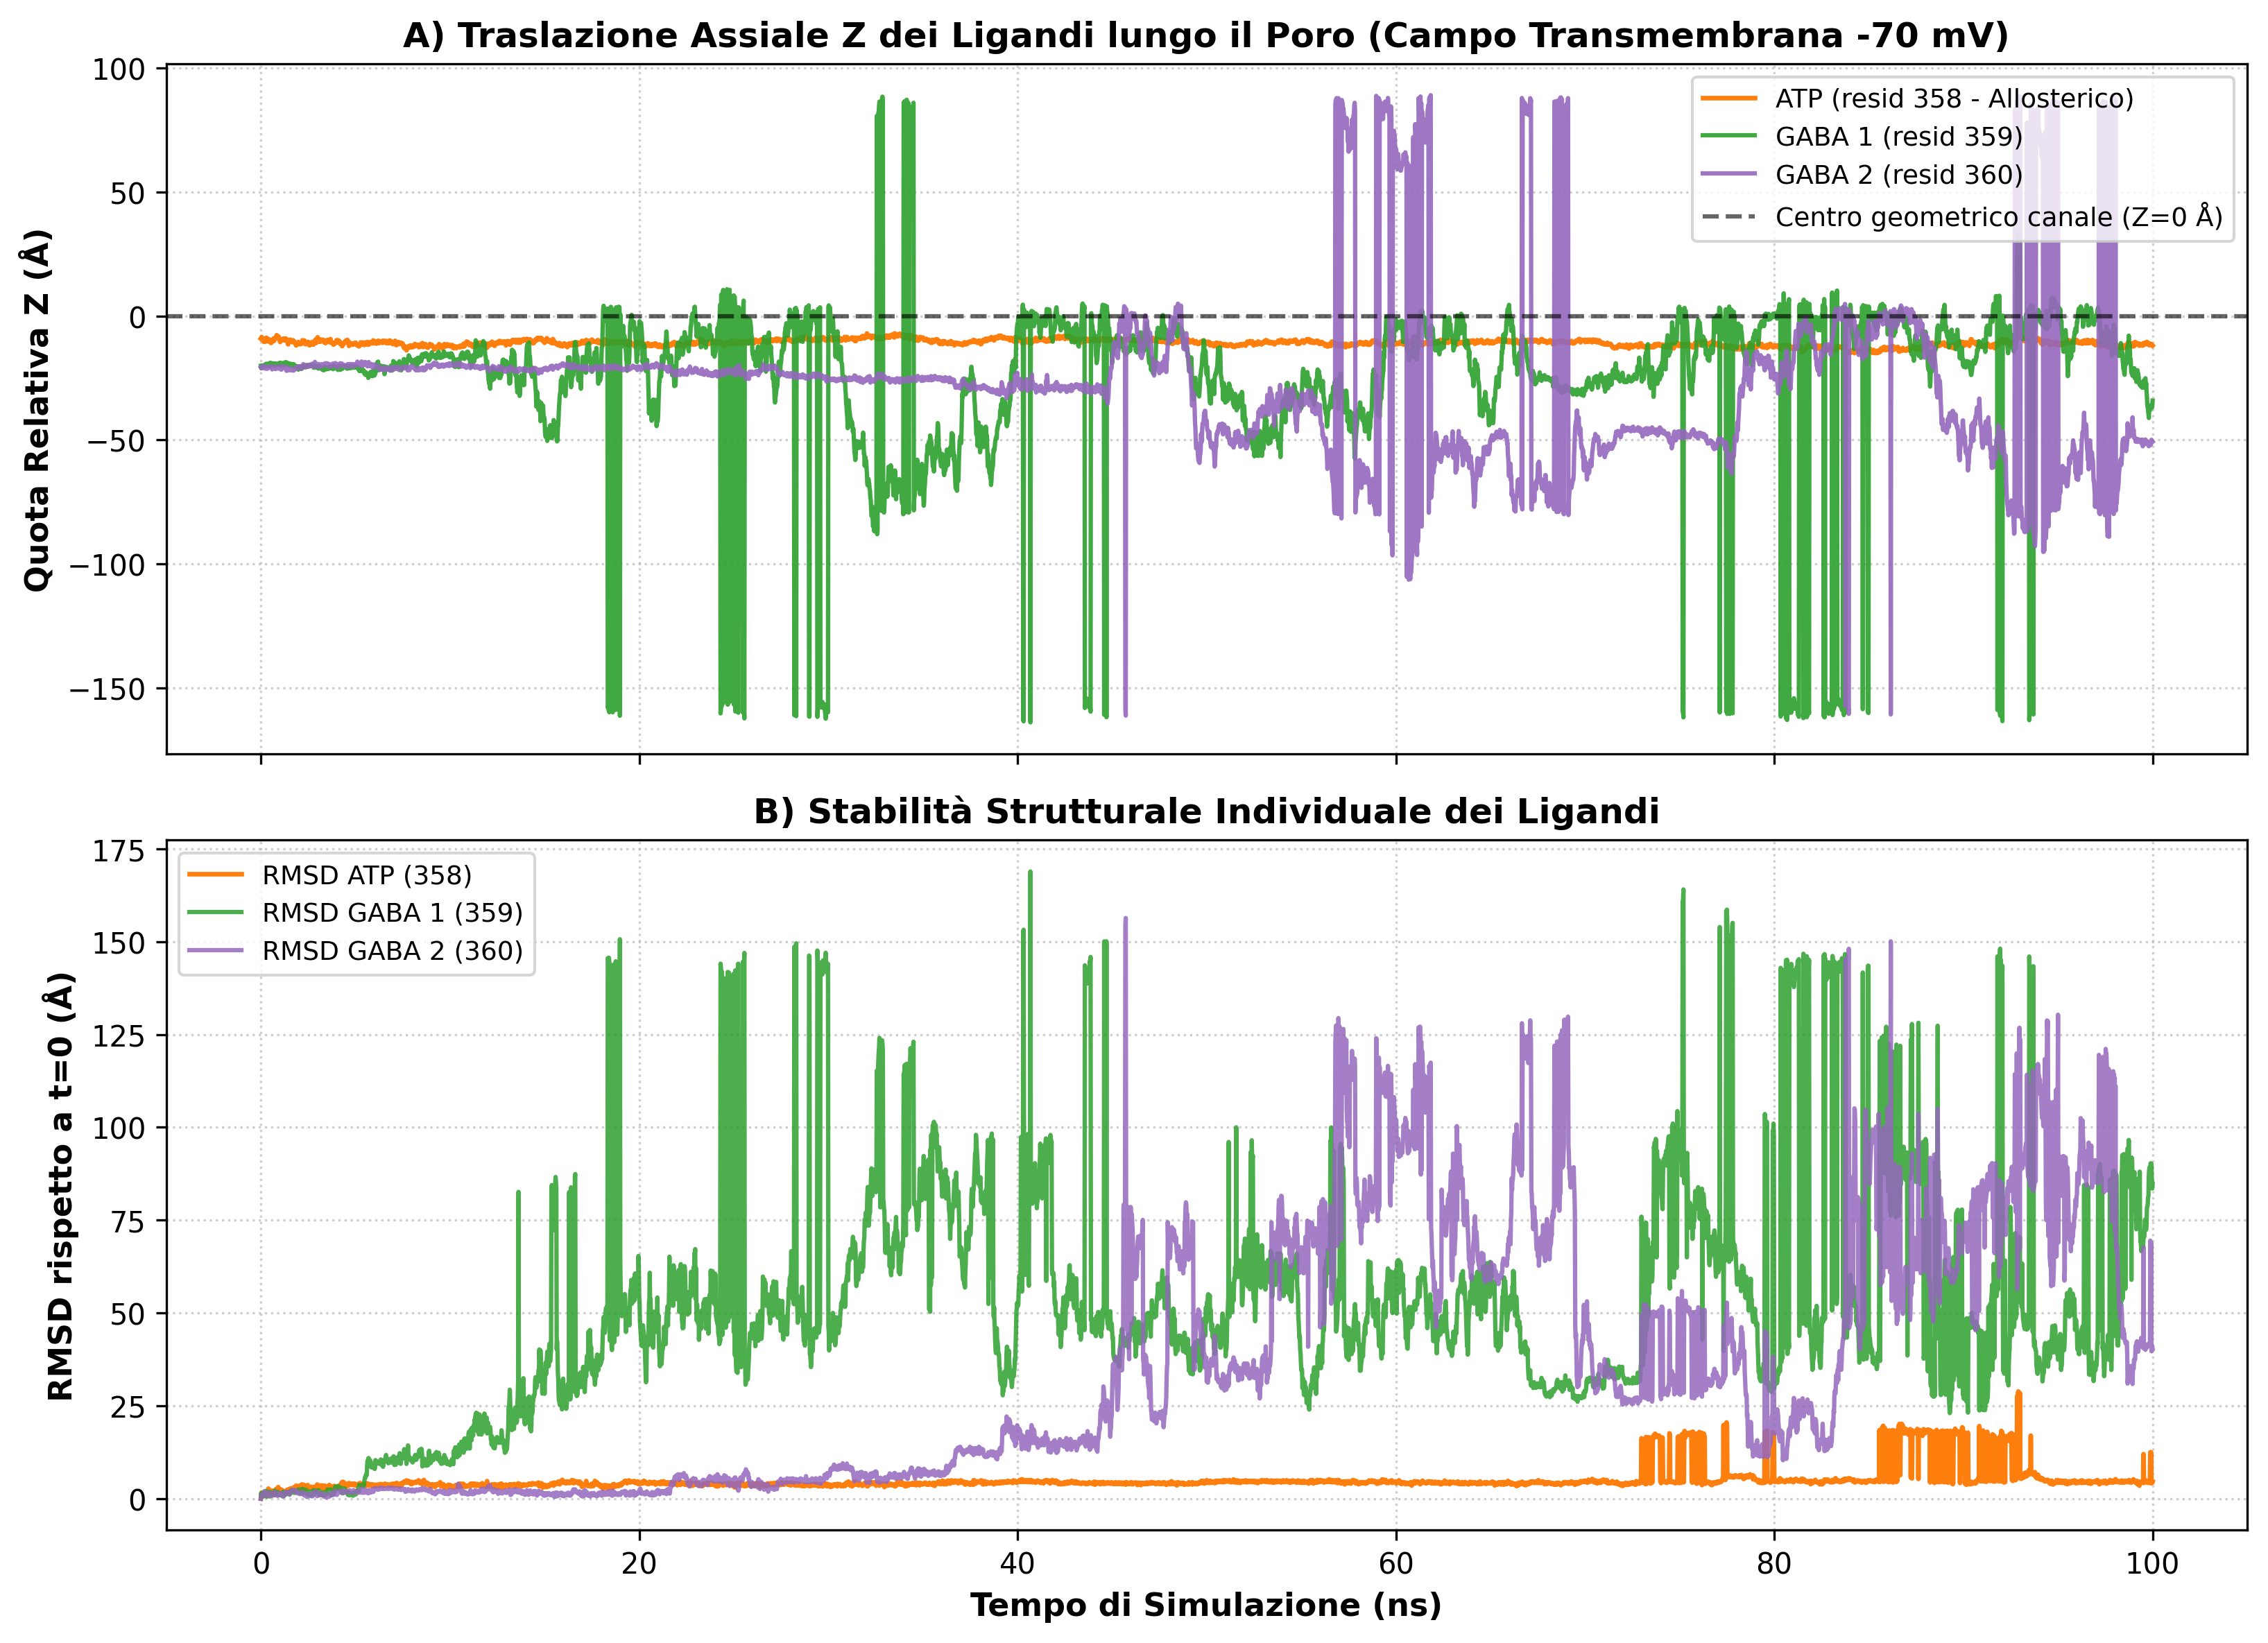


=== RIEPILOGO STATISTICO ===
ATP (358): Z media = -10.81 ± 1.75 Å | RMSD medio = 5.14 Å
GABA 1 (359): Z media = -25.03 ± 34.58 Å | RMSD medio = 52.06 Å
GABA 2 (360): Z media = -26.68 ± 32.68 Å | RMSD medio = 36.36 Å


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from MDAnalysis.analysis import rms

# 1. Selezioni atomiche specifiche
sel_protein = u.select_atoms("protein")
sel_atp     = u.select_atoms("resid 358 and resname ATP")
sel_gaba1   = u.select_atoms("resid 359 and resname GAB")
sel_gaba2   = u.select_atoms("resid 360 and resname GAB")

time_ns = []
z_atp_rel = []
z_gaba1_rel = []
z_gaba2_rel = []

print("Calcolo delle coordinate Z lungo la traiettoria (5001 frame)...")
for ts in u.trajectory:
    t_ns = ts.time / 1000.0
    time_ns.append(t_ns)

    # Quota Z del centro di massa della proteina come zero di riferimento
    z_prot = sel_protein.center_of_mass()[2]

    z_atp_rel.append(sel_atp.center_of_mass()[2] - z_prot)
    z_gaba1_rel.append(sel_gaba1.center_of_mass()[2] - z_prot)
    z_gaba2_rel.append(sel_gaba2.center_of_mass()[2] - z_prot)

time_ns = np.array(time_ns)
z_atp_rel = np.array(z_atp_rel)
z_gaba1_rel = np.array(z_gaba1_rel)
z_gaba2_rel = np.array(z_gaba2_rel)

# 2. Calcolo RMSD individuale per ciascun ligando (con fit sul backbone del recettore)
print("Calcolo RMSD individuale per ATP, GABA-359 e GABA-360...")
R_ind = rms.RMSD(u, u,
                 select='backbone',
                 groupselections=[
                     'resid 358 and resname ATP',
                     'resid 359 and resname GAB',
                     'resid 360 and resname GAB'
                 ],
                 ref_frame=0)
R_ind.run()

rmsd_atp   = R_ind.results.rmsd[:, 3]
rmsd_gaba1 = R_ind.results.rmsd[:, 4]
rmsd_gaba2 = R_ind.results.rmsd[:, 5]

# 3. Plot a due pannelli per l'articolo
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), dpi=300, sharex=True)

# Pannello A: Quota Assiale Z
ax1.plot(time_ns, z_atp_rel, label="ATP (resid 358 - Allosterico)", color="#ff7f0e", lw=1.6)
ax1.plot(time_ns, z_gaba1_rel, label="GABA 1 (resid 359)", color="#2ca02c", lw=1.5, alpha=0.9)
ax1.plot(time_ns, z_gaba2_rel, label="GABA 2 (resid 360)", color="#9467bd", lw=1.5, alpha=0.9)
ax1.axhline(0, color="black", linestyle="--", alpha=0.6, label="Centro geometrico canale (Z=0 Å)")
ax1.set_ylabel("Quota Relativa Z (Å)", fontsize=11, fontweight='bold')
ax1.set_title("A) Traslazione Assiale Z dei Ligandi lungo il Poro (Campo Transmembrana -70 mV)", fontsize=12, fontweight='bold')
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right", frameon=True, fontsize=9)

# Pannello B: RMSD Individuale
ax2.plot(time_ns, rmsd_atp, label="RMSD ATP (358)", color="#ff7f0e", lw=1.6)
ax2.plot(time_ns, rmsd_gaba1, label="RMSD GABA 1 (359)", color="#2ca02c", lw=1.5, alpha=0.85)
ax2.plot(time_ns, rmsd_gaba2, label="RMSD GABA 2 (360)", color="#9467bd", lw=1.5, alpha=0.85)
ax2.set_xlabel("Tempo di Simulazione (ns)", fontsize=11, fontweight='bold')
ax2.set_ylabel("RMSD rispetto a t=0 (Å)", fontsize=11, fontweight='bold')
ax2.set_title("B) Stabilità Strutturale Individuale dei Ligandi", fontsize=12, fontweight='bold')
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper left", frameon=True, fontsize=9)

plt.tight_layout()
plt.savefig("analisi_dinamica_ligandi_100ns.png", dpi=300)
plt.show()

print("\n=== RIEPILOGO STATISTICO ===")
print(f"ATP (358): Z media = {np.mean(z_atp_rel):.2f} ± {np.std(z_atp_rel):.2f} Å | RMSD medio = {np.mean(rmsd_atp):.2f} Å")
print(f"GABA 1 (359): Z media = {np.mean(z_gaba1_rel):.2f} ± {np.std(z_gaba1_rel):.2f} Å | RMSD medio = {np.mean(rmsd_gaba1):.2f} Å")
print(f"GABA 2 (360): Z media = {np.mean(z_gaba2_rel):.2f} ± {np.std(z_gaba2_rel):.2f} Å | RMSD medio = {np.mean(rmsd_gaba2):.2f} Å")

Calcolo del raggio medio del gate nel tempo (5001 frame)...


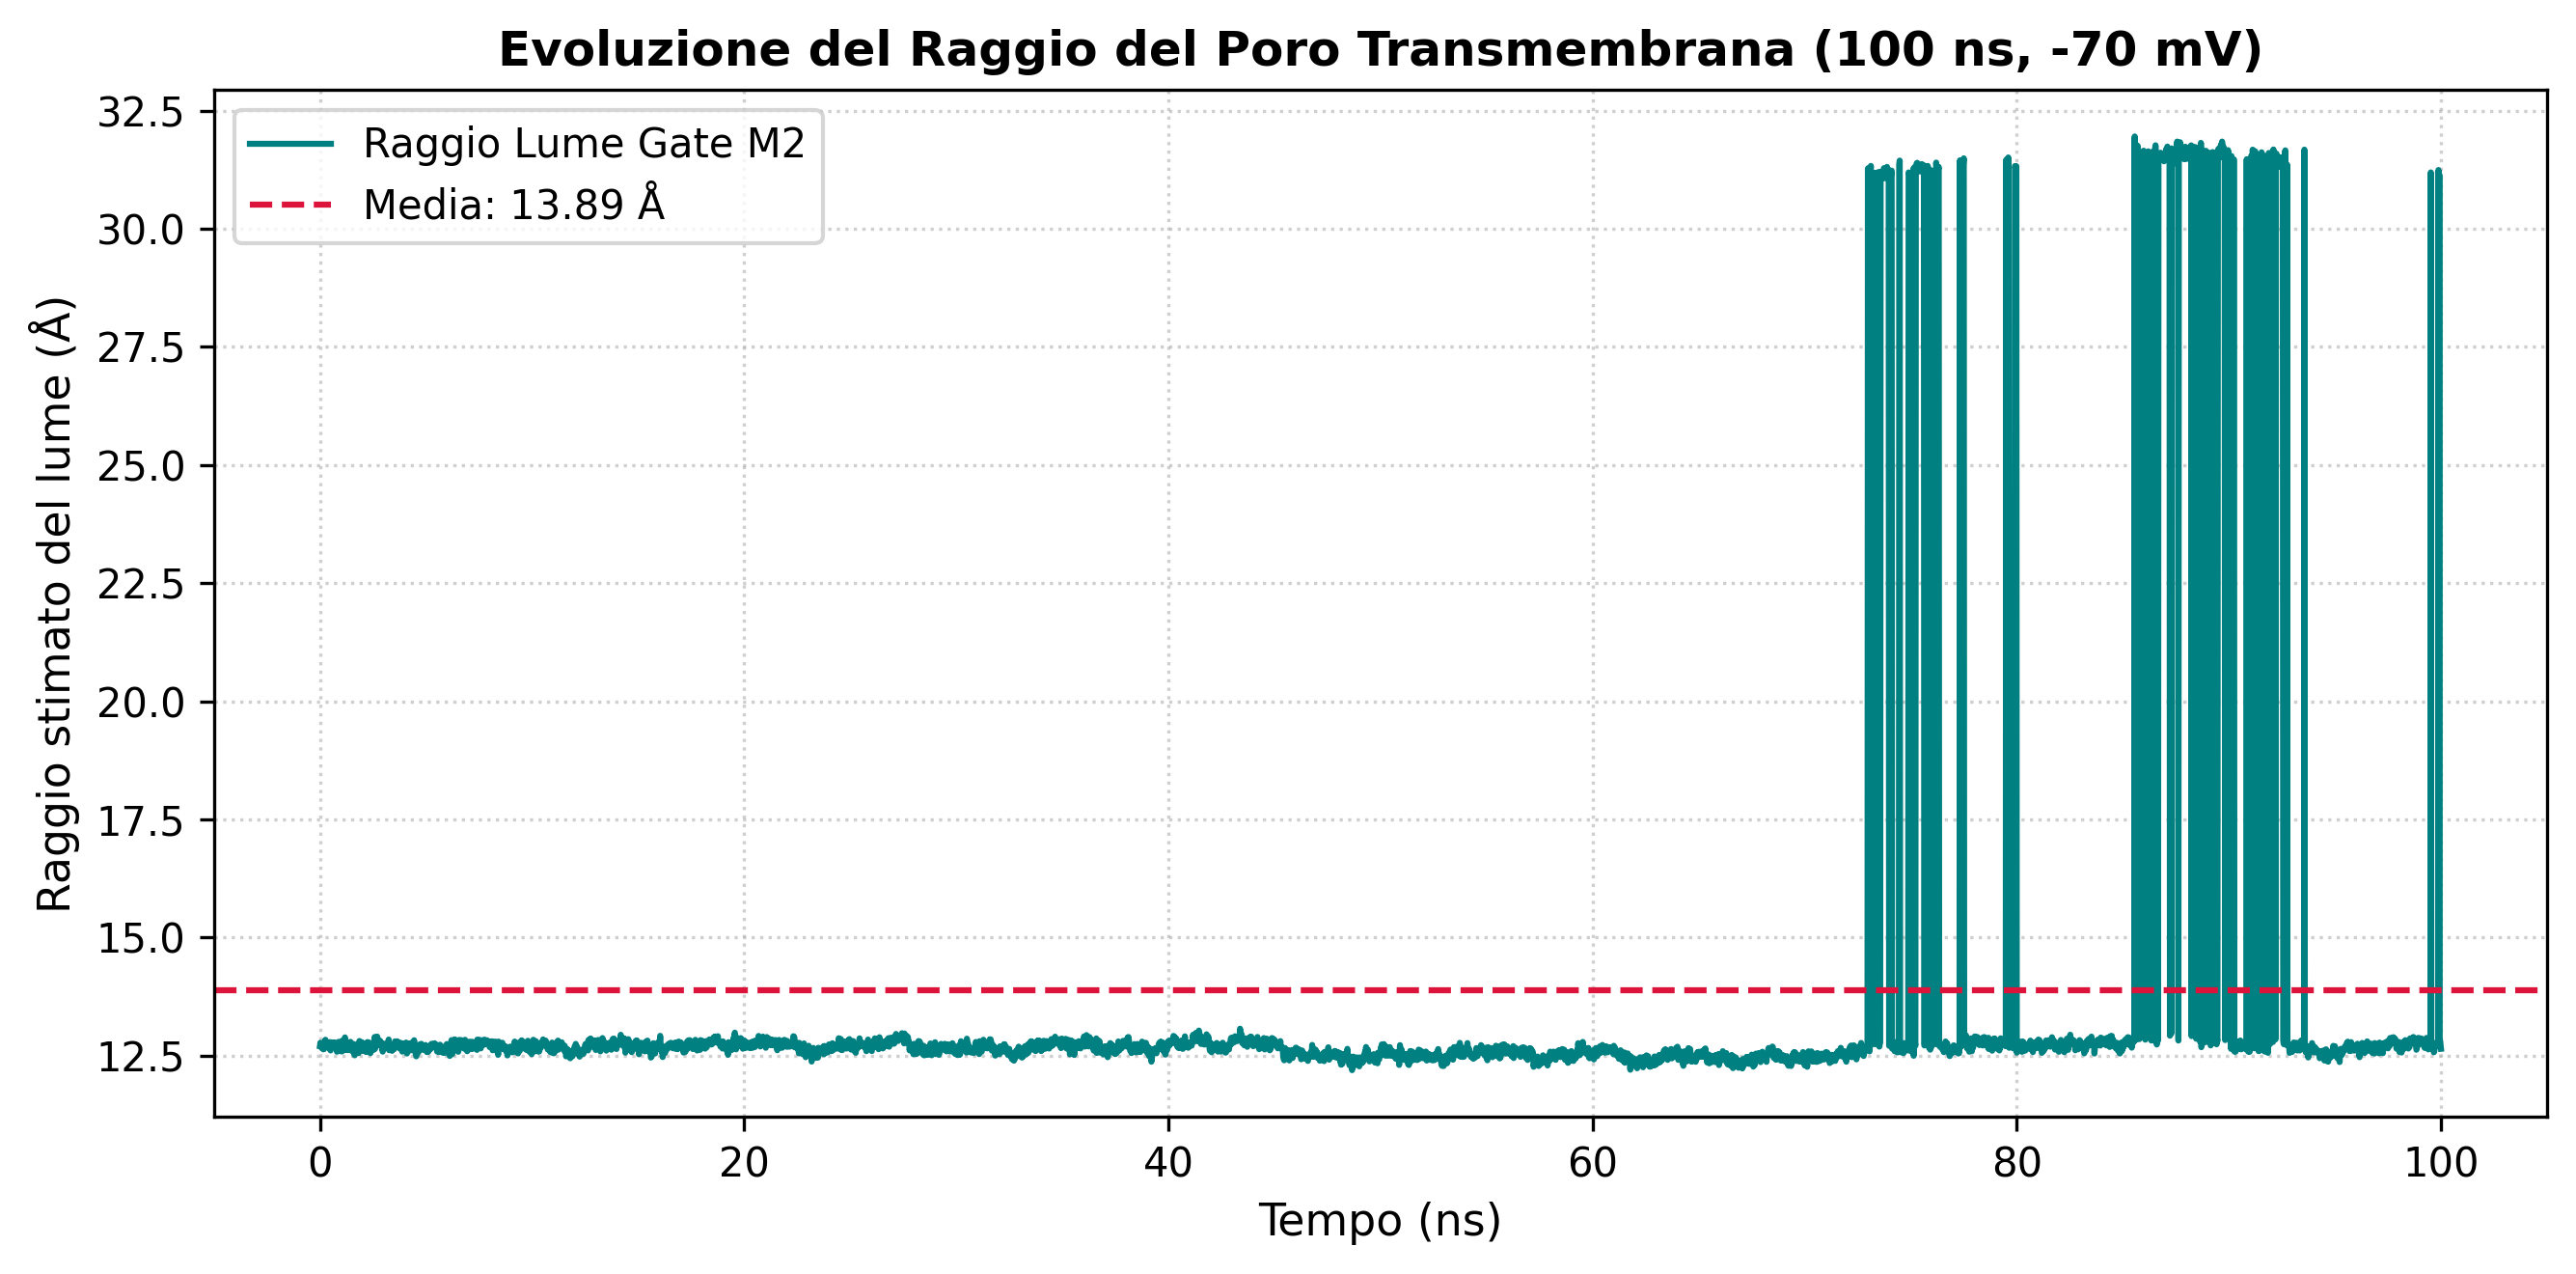

Raggio del gate: iniziale = 12.70 Å | finale = 12.64 Å | medio = 13.89 Å


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Selezioniamo i carboni alfa delle eliche M2 che formano la parete del poro.
# Nelle catene del recettore GABAA, il residuo centrale idrofobico del gate (9' Leucina)
# corrisponde tipicamente ai residui attorno a Leu270-Leu285 (a seconda dell'allineamento).
# Selezioniamo i residui del poro transmembrana con raggio verso l'asse centrale Z:
pore_ca = u.select_atoms("protein and name CA and (resid 260 to 290)")

times = []
pore_radii = []

print("Calcolo del raggio medio del gate nel tempo (5001 frame)...")
for ts in u.trajectory:
    t_ns = ts.time / 1000.0
    times.append(t_ns)

    # Centro del poro su XY
    com_xy = pore_ca.center_of_mass()[:2]
    pos_xy = pore_ca.positions[:, :2]

    # Raggio medio dei CA rispetto al centro geometrico del canale
    dists = np.linalg.norm(pos_xy - com_xy, axis=1)
    pore_radii.append(np.mean(dists))

times = np.array(times)
pore_radii = np.array(pore_radii)

# Sottraiamo il raggio di Van der Waals medio del backbone (~2.0 Å) per ottenere il raggio utile di lume
lumen_radius = pore_radii - 2.0

plt.figure(figsize=(9, 4.5), dpi=300)
plt.plot(times, lumen_radius, color="#008080", lw=1.5, label="Raggio Lume Gate M2")
plt.axhline(np.mean(lumen_radius), color="crimson", ls="--", label=f"Media: {np.mean(lumen_radius):.2f} Å")

plt.title("Evoluzione del Raggio del Poro Transmembrana (100 ns, -70 mV)", fontsize=12, fontweight='bold')
plt.xlabel("Tempo (ns)", fontsize=11)
plt.ylabel("Raggio stimato del lume (Å)", fontsize=11)
plt.grid(True, ls=":", alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig("evoluzione_raggio_poro.png", dpi=300)
plt.show()

print(f"Raggio del gate: iniziale = {lumen_radius[0]:.2f} Å | finale = {lumen_radius[-1]:.2f} Å | medio = {np.mean(lumen_radius):.2f} Å")

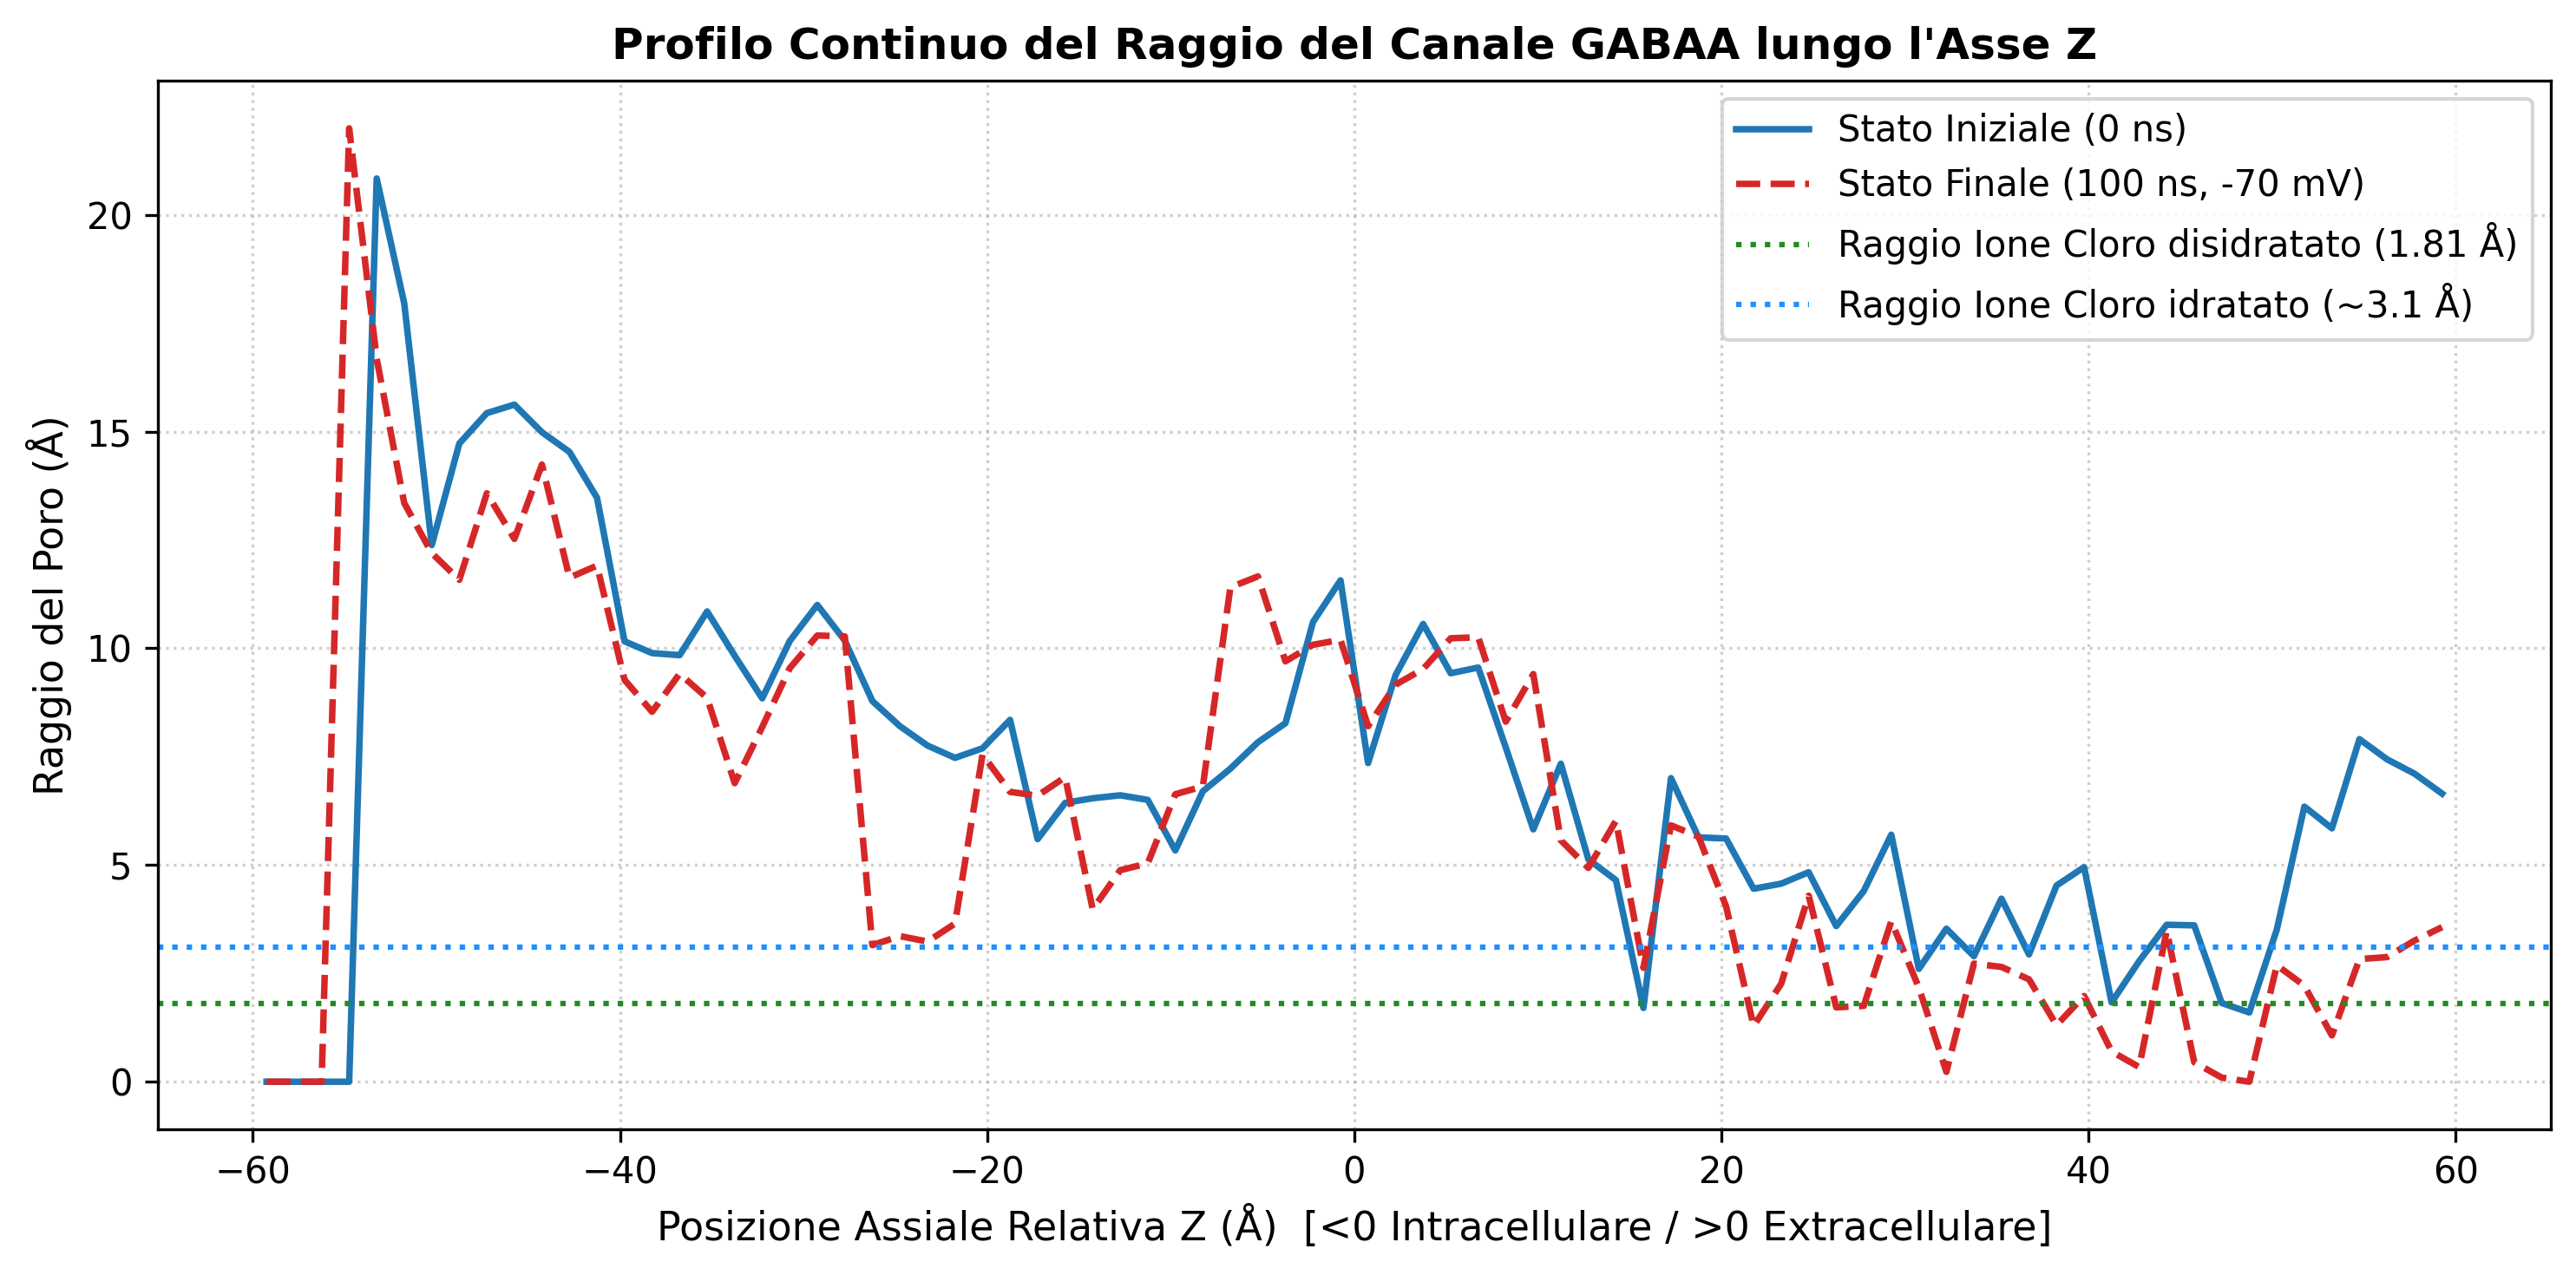

Collo di bottiglia iniziale: min raggio = 1.60 Å alla quota Z = 42.8 Å
Collo di bottiglia finale:   min raggio = 0.10 Å alla quota Z = 42.8 Å


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Definizione asse Z relativo al centro di massa della proteina
z_bins = np.linspace(-60, 60, 81)  # step di 1.5 Å
bin_centers = 0.5 * (z_bins[:-1] + z_bins[1:])

sel_prot = u.select_atoms("protein")
sel_heavy = u.select_atoms("protein and not name H*")

def compute_pore_profile_frame():
    com_p = sel_prot.center_of_mass()
    coords = sel_heavy.positions - com_p  # centratura sul COM

    r_profile = []
    for i in range(len(z_bins) - 1):
        z_min, z_max = z_bins[i], z_bins[i+1]
        mask = (coords[:, 2] >= z_min) & (coords[:, 2] < z_max)
        if np.any(mask):
            slice_coords = coords[mask]
            # Distanza radiale XY dall'asse centrale Z=0
            radii_xy = np.sqrt(slice_coords[:, 0]**2 + slice_coords[:, 1]**2)
            # Raggio minimo meno raggio di van der Waals medio (~1.4 Å)
            r_profile.append(max(0.0, np.min(radii_xy) - 1.4))
        else:
            r_profile.append(0.0)
    return np.array(r_profile)

# Calcolo su frame 0 (inizio) e frame -1 (fine)
u.trajectory[0]
r_initial = compute_pore_profile_frame()

u.trajectory[-1]
r_final = compute_pore_profile_frame()

# Plot del profilo completo
plt.figure(figsize=(10, 5), dpi=300)
plt.plot(bin_centers, r_initial, label="Stato Iniziale (0 ns)", color="#1f77b4", lw=1.8)
plt.plot(bin_centers, r_final, label="Stato Finale (100 ns, -70 mV)", color="#d62728", lw=1.8, ls="--")

# Riferimenti biologici
plt.axhline(1.81, color="forestgreen", ls=":", label="Raggio Ione Cloro disidratato (1.81 Å)")
plt.axhline(3.1, color="dodgerblue", ls=":", label="Raggio Ione Cloro idratato (~3.1 Å)")

plt.title("Profilo Continuo del Raggio del Canale GABAA lungo l'Asse Z", fontsize=12, fontweight='bold')
plt.xlabel("Posizione Assiale Relativa Z (Å)  [<0 Intracellulare / >0 Extracellulare]", fontsize=11)
plt.ylabel("Raggio del Poro (Å)", fontsize=11)
plt.grid(True, ls=":", alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig("profilo_continuo_poro_z.png", dpi=300)
plt.show()

# Stampa colli di bottiglia
print(f"Collo di bottiglia iniziale: min raggio = {np.min(r_initial[r_initial>0]):.2f} Å alla quota Z = {bin_centers[np.argmin(r_initial[r_initial>0])]:.1f} Å")
print(f"Collo di bottiglia finale:   min raggio = {np.min(r_final[r_final>0]):.2f} Å alla quota Z = {bin_centers[np.argmin(r_final[r_final>0])]:.1f} Å")

Campionamento assiale di ioni e solvente nel lume (passo 5 frame)...


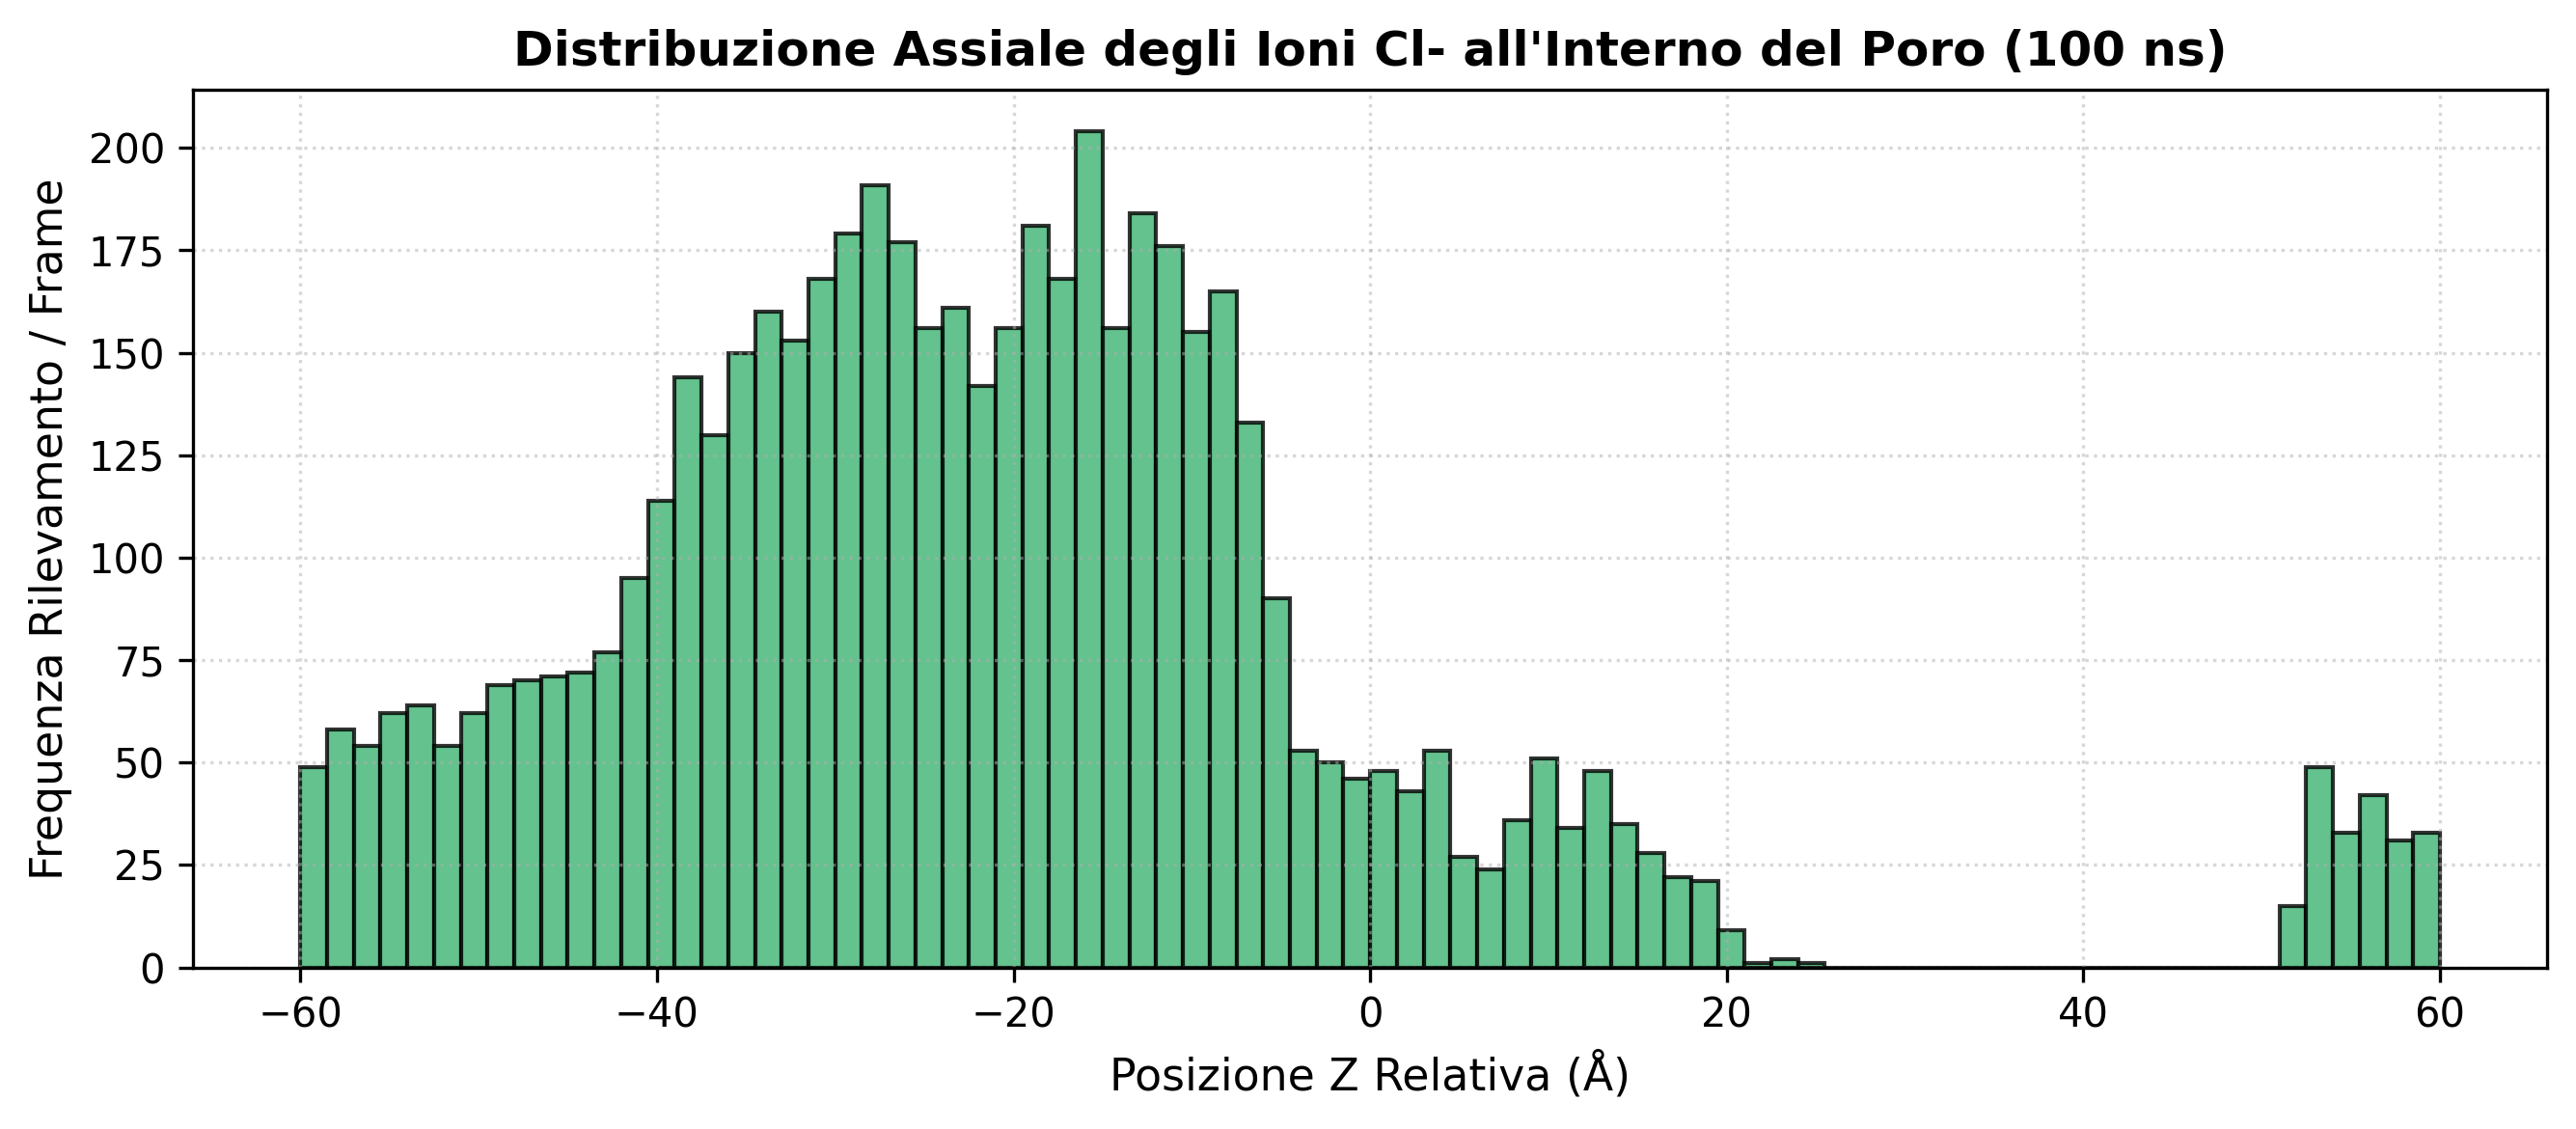

In [ ]:
# Selezioni per ioni Cl- e acque
# Nei modelli CHARMM-GUI solitamente CLA o CL, e TIP3
ions_cl = u.select_atoms("resname CLA or resname CL")
waters = u.select_atoms("resname TIP3 and name OH2")

z_cl_history = []
z_wat_history = []

print("Campionamento assiale di ioni e solvente nel lume (passo 5 frame)...")
for ts in u.trajectory[::5]:  # campiona ogni 5 frame per velocità
    com_p = sel_prot.center_of_mass()

    # Cloruri entro 10 Å dall'asse del canale
    cl_pos = ions_cl.positions - com_p
    r_cl = np.sqrt(cl_pos[:, 0]**2 + cl_pos[:, 1]**2)
    inside_pore_cl = cl_pos[r_cl < 10.0, 2]
    z_cl_history.extend(inside_pore_cl)

# Istogramma di densità lungo Z
plt.figure(figsize=(9, 4), dpi=300)
plt.hist(z_cl_history, bins=80, range=(-60, 60), color="mediumseagreen", alpha=0.8, edgecolor="black", lw=0.5)
plt.title("Distribuzione Assiale degli Ioni Cl- all'Interno del Poro (100 ns)", fontsize=12, fontweight='bold')
plt.xlabel("Posizione Z Relativa (Å)", fontsize=11)
plt.ylabel("Frequenza Rilevamento / Frame", fontsize=11)
plt.grid(True, ls=":", alpha=0.5)
plt.tight_layout()
plt.savefig("densita_cloruro_poro.png", dpi=300)
plt.show()

Calcolo matrice R(z, t): 501 frame x 80 fette spaziali...
✅ Matrice salvata con successo in 'matrice_poro_zt.npz'!


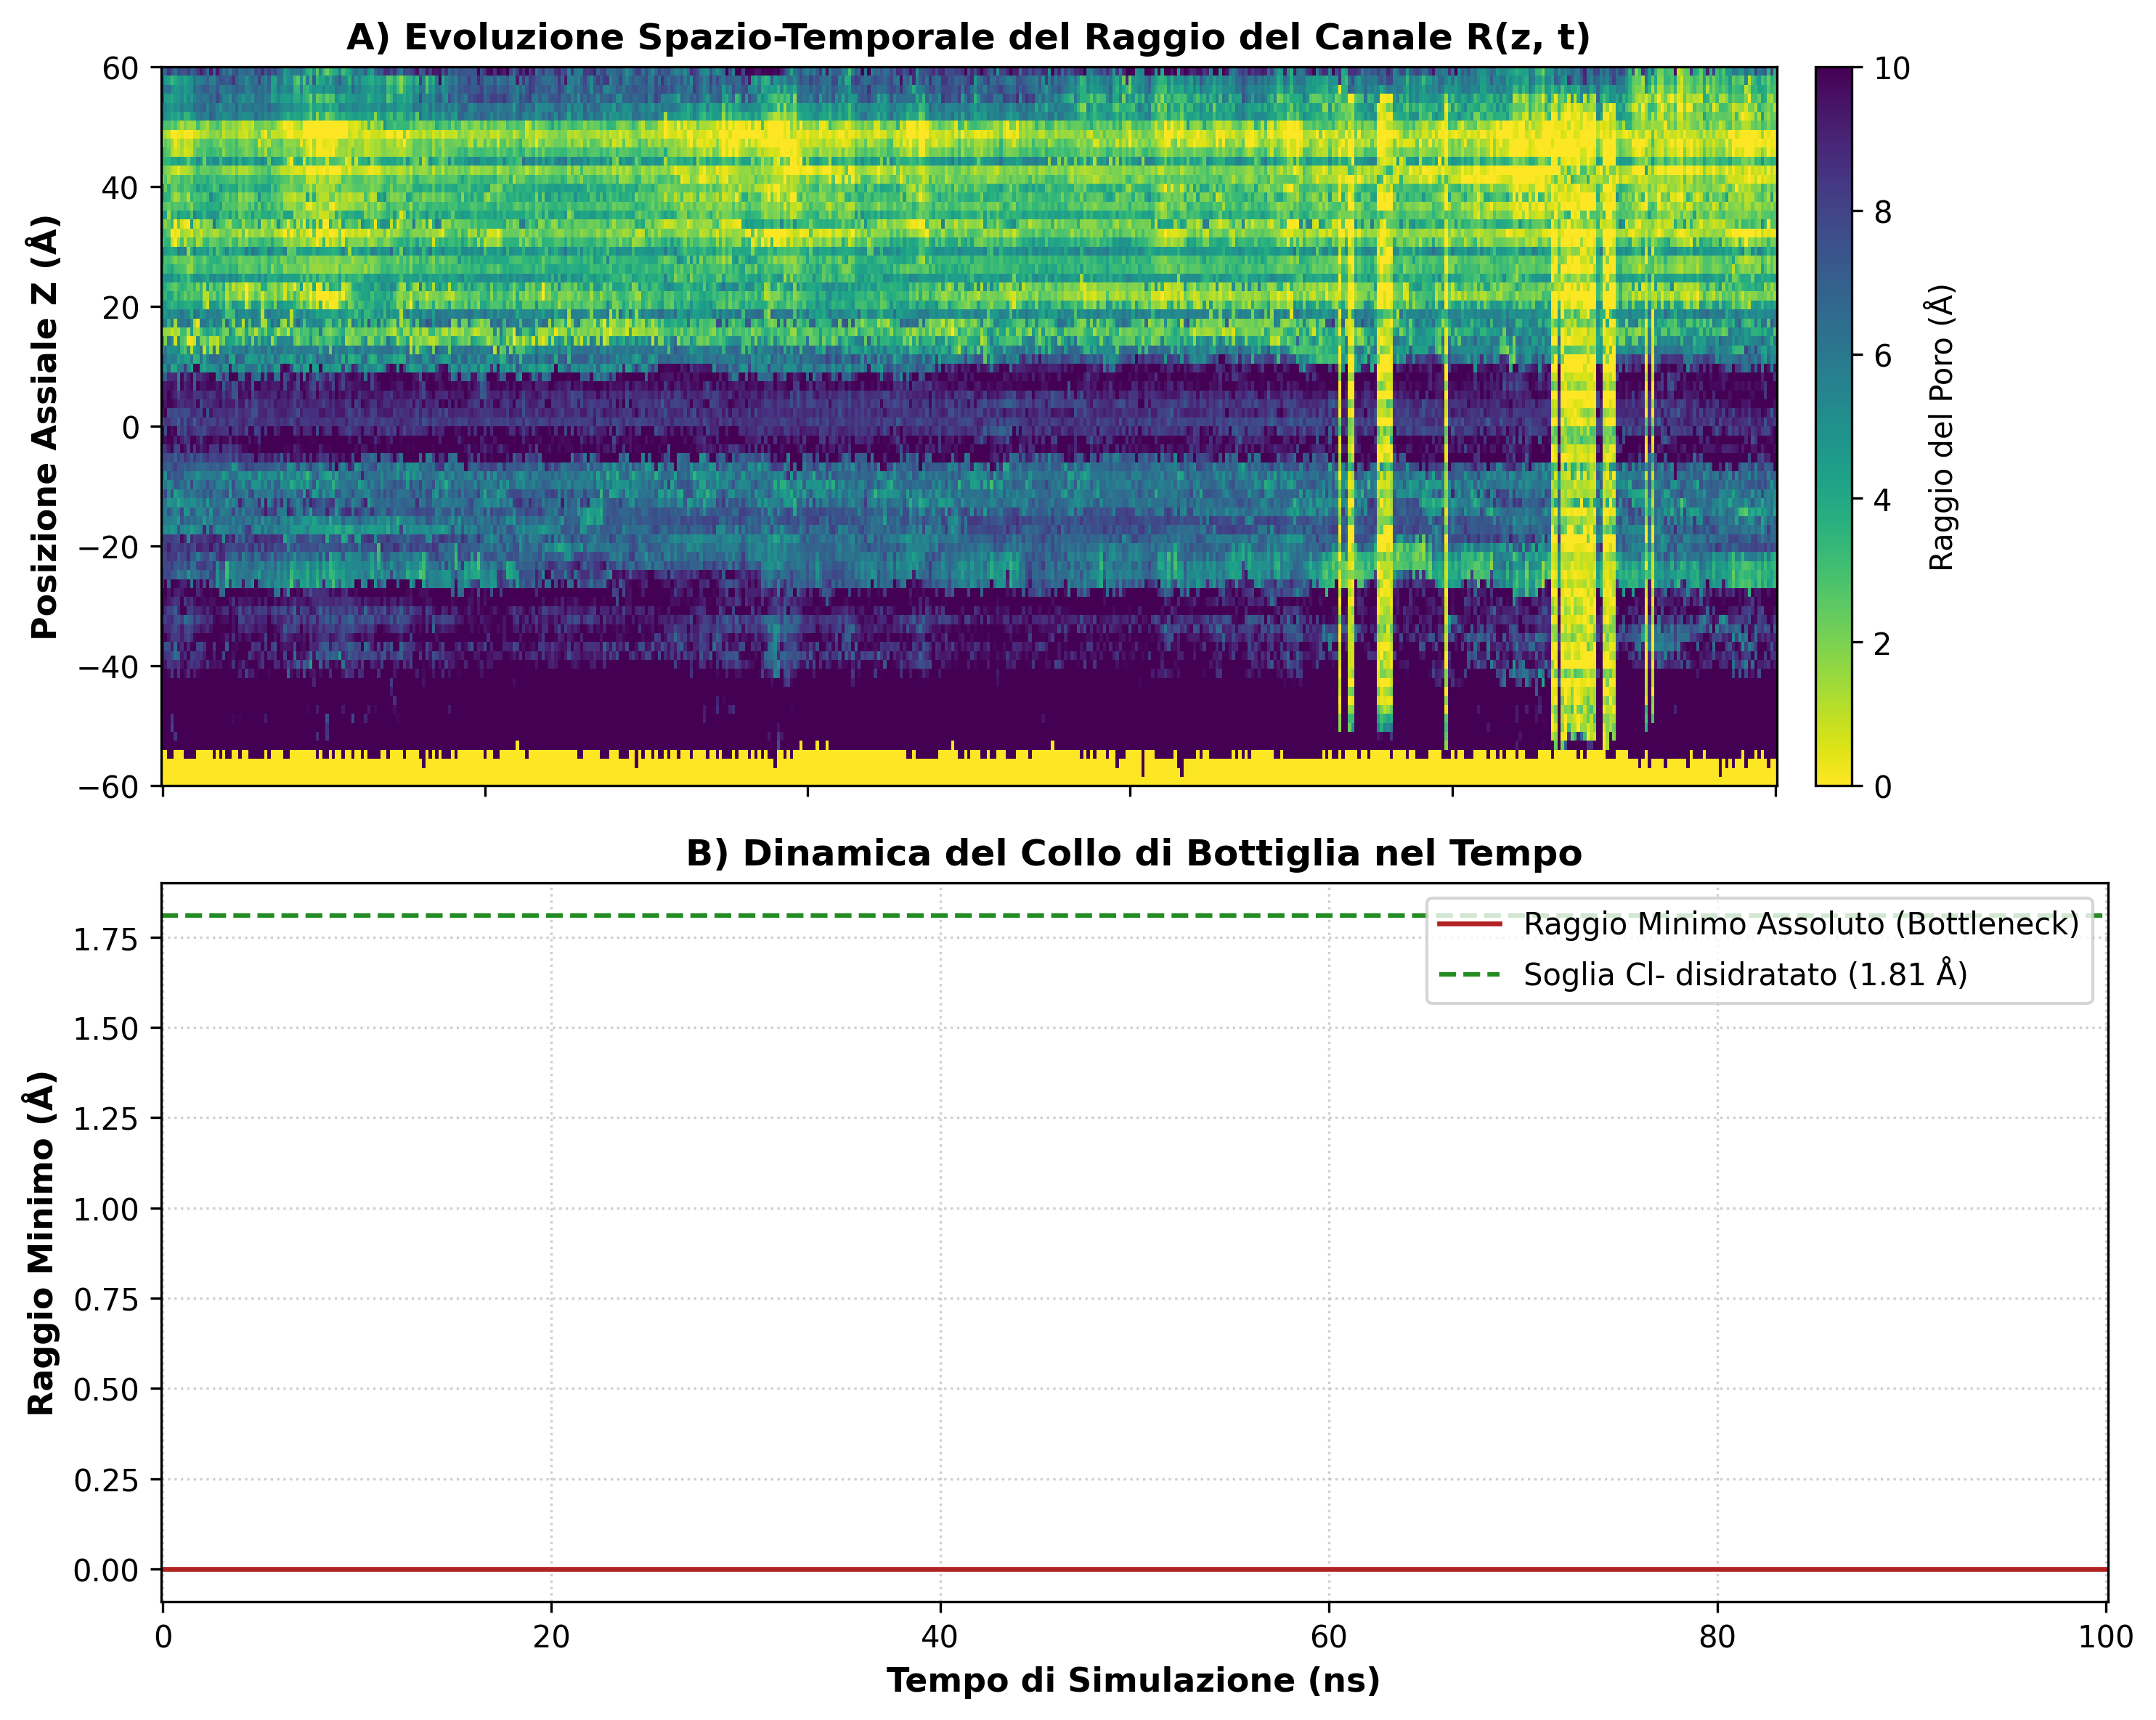

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Griglia spaziale Z (80 intervalli da -60 a +60 Å, passo 1.5 Å)
z_bins = np.linspace(-60, 60, 81)
bin_centers = 0.5 * (z_bins[:-1] + z_bins[1:])

sel_prot = u.select_atoms("protein")
sel_heavy = u.select_atoms("protein and not name H*")

# Campioniamo ogni 10 frame (501 frame totali lungo i 100 ns)
stride = 10
sampled_frames = u.trajectory[::stride]
n_frames = len(sampled_frames)
n_bins = len(bin_centers)

R_matrix = np.zeros((n_frames, n_bins))
time_array = np.zeros(n_frames)

print(f"Calcolo matrice R(z, t): {n_frames} frame x {n_bins} fette spaziali...")

for f_idx, ts in enumerate(sampled_frames):
    time_array[f_idx] = ts.time / 1000.0  # tempo in ns
    com_p = sel_prot.center_of_mass()
    coords = sel_heavy.positions - com_p

    for b_idx in range(n_bins):
        z_min, z_max = z_bins[b_idx], z_bins[b_idx+1]
        mask = (coords[:, 2] >= z_min) & (coords[:, 2] < z_max)
        if np.any(mask):
            slice_coords = coords[mask]
            radii_xy = np.sqrt(slice_coords[:, 0]**2 + slice_coords[:, 1]**2)
            r_val = max(0.0, np.min(radii_xy) - 1.4)
            R_matrix[f_idx, b_idx] = r_val
        else:
            R_matrix[f_idx, b_idx] = 0.0

# 2. Salvataggio su file compresso (occupa solo ~300 KB!)
np.savez_compressed("matrice_poro_zt.npz",
                    R_matrix=R_matrix,
                    time=time_array,
                    z_bins=bin_centers)
print("✅ Matrice salvata con successo in 'matrice_poro_zt.npz'!")

# 3. Tracciamento del collo di bottiglia minimo nel tempo
bottleneck_time = np.min(R_matrix, axis=1)

# 4. Generazione Mappa di Contorno 2D Spazio-Tempo (Heatmap)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=300, sharex=True)

# Heatmap R(z, t)
im = ax1.pcolormesh(time_array, bin_centers, R_matrix.T, cmap="viridis_r", shading="auto", vmin=0, vmax=10)
cbar = fig.colorbar(im, ax=ax1, pad=0.02)
cbar.set_label("Raggio del Poro (Å)", fontsize=10)
ax1.set_ylabel("Posizione Assiale Z (Å)", fontsize=11, fontweight='bold')
ax1.set_title("A) Evoluzione Spazio-Temporale del Raggio del Canale R(z, t)", fontsize=12, fontweight='bold')

# Bottleneck nel tempo
ax2.plot(time_array, bottleneck_time, color="firebrick", lw=1.6, label="Raggio Minimo Assoluto (Bottleneck)")
ax2.axhline(1.81, color="forestgreen", ls="--", label="Soglia Cl- disidratato (1.81 Å)")
ax2.set_xlabel("Tempo di Simulazione (ns)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Raggio Minimo (Å)", fontsize=11, fontweight='bold')
ax2.set_title("B) Dinamica del Collo di Bottiglia nel Tempo", fontsize=12, fontweight='bold')
ax2.grid(True, ls=":", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("mappa_dinamica_poro_2d.png", dpi=300)
plt.show()

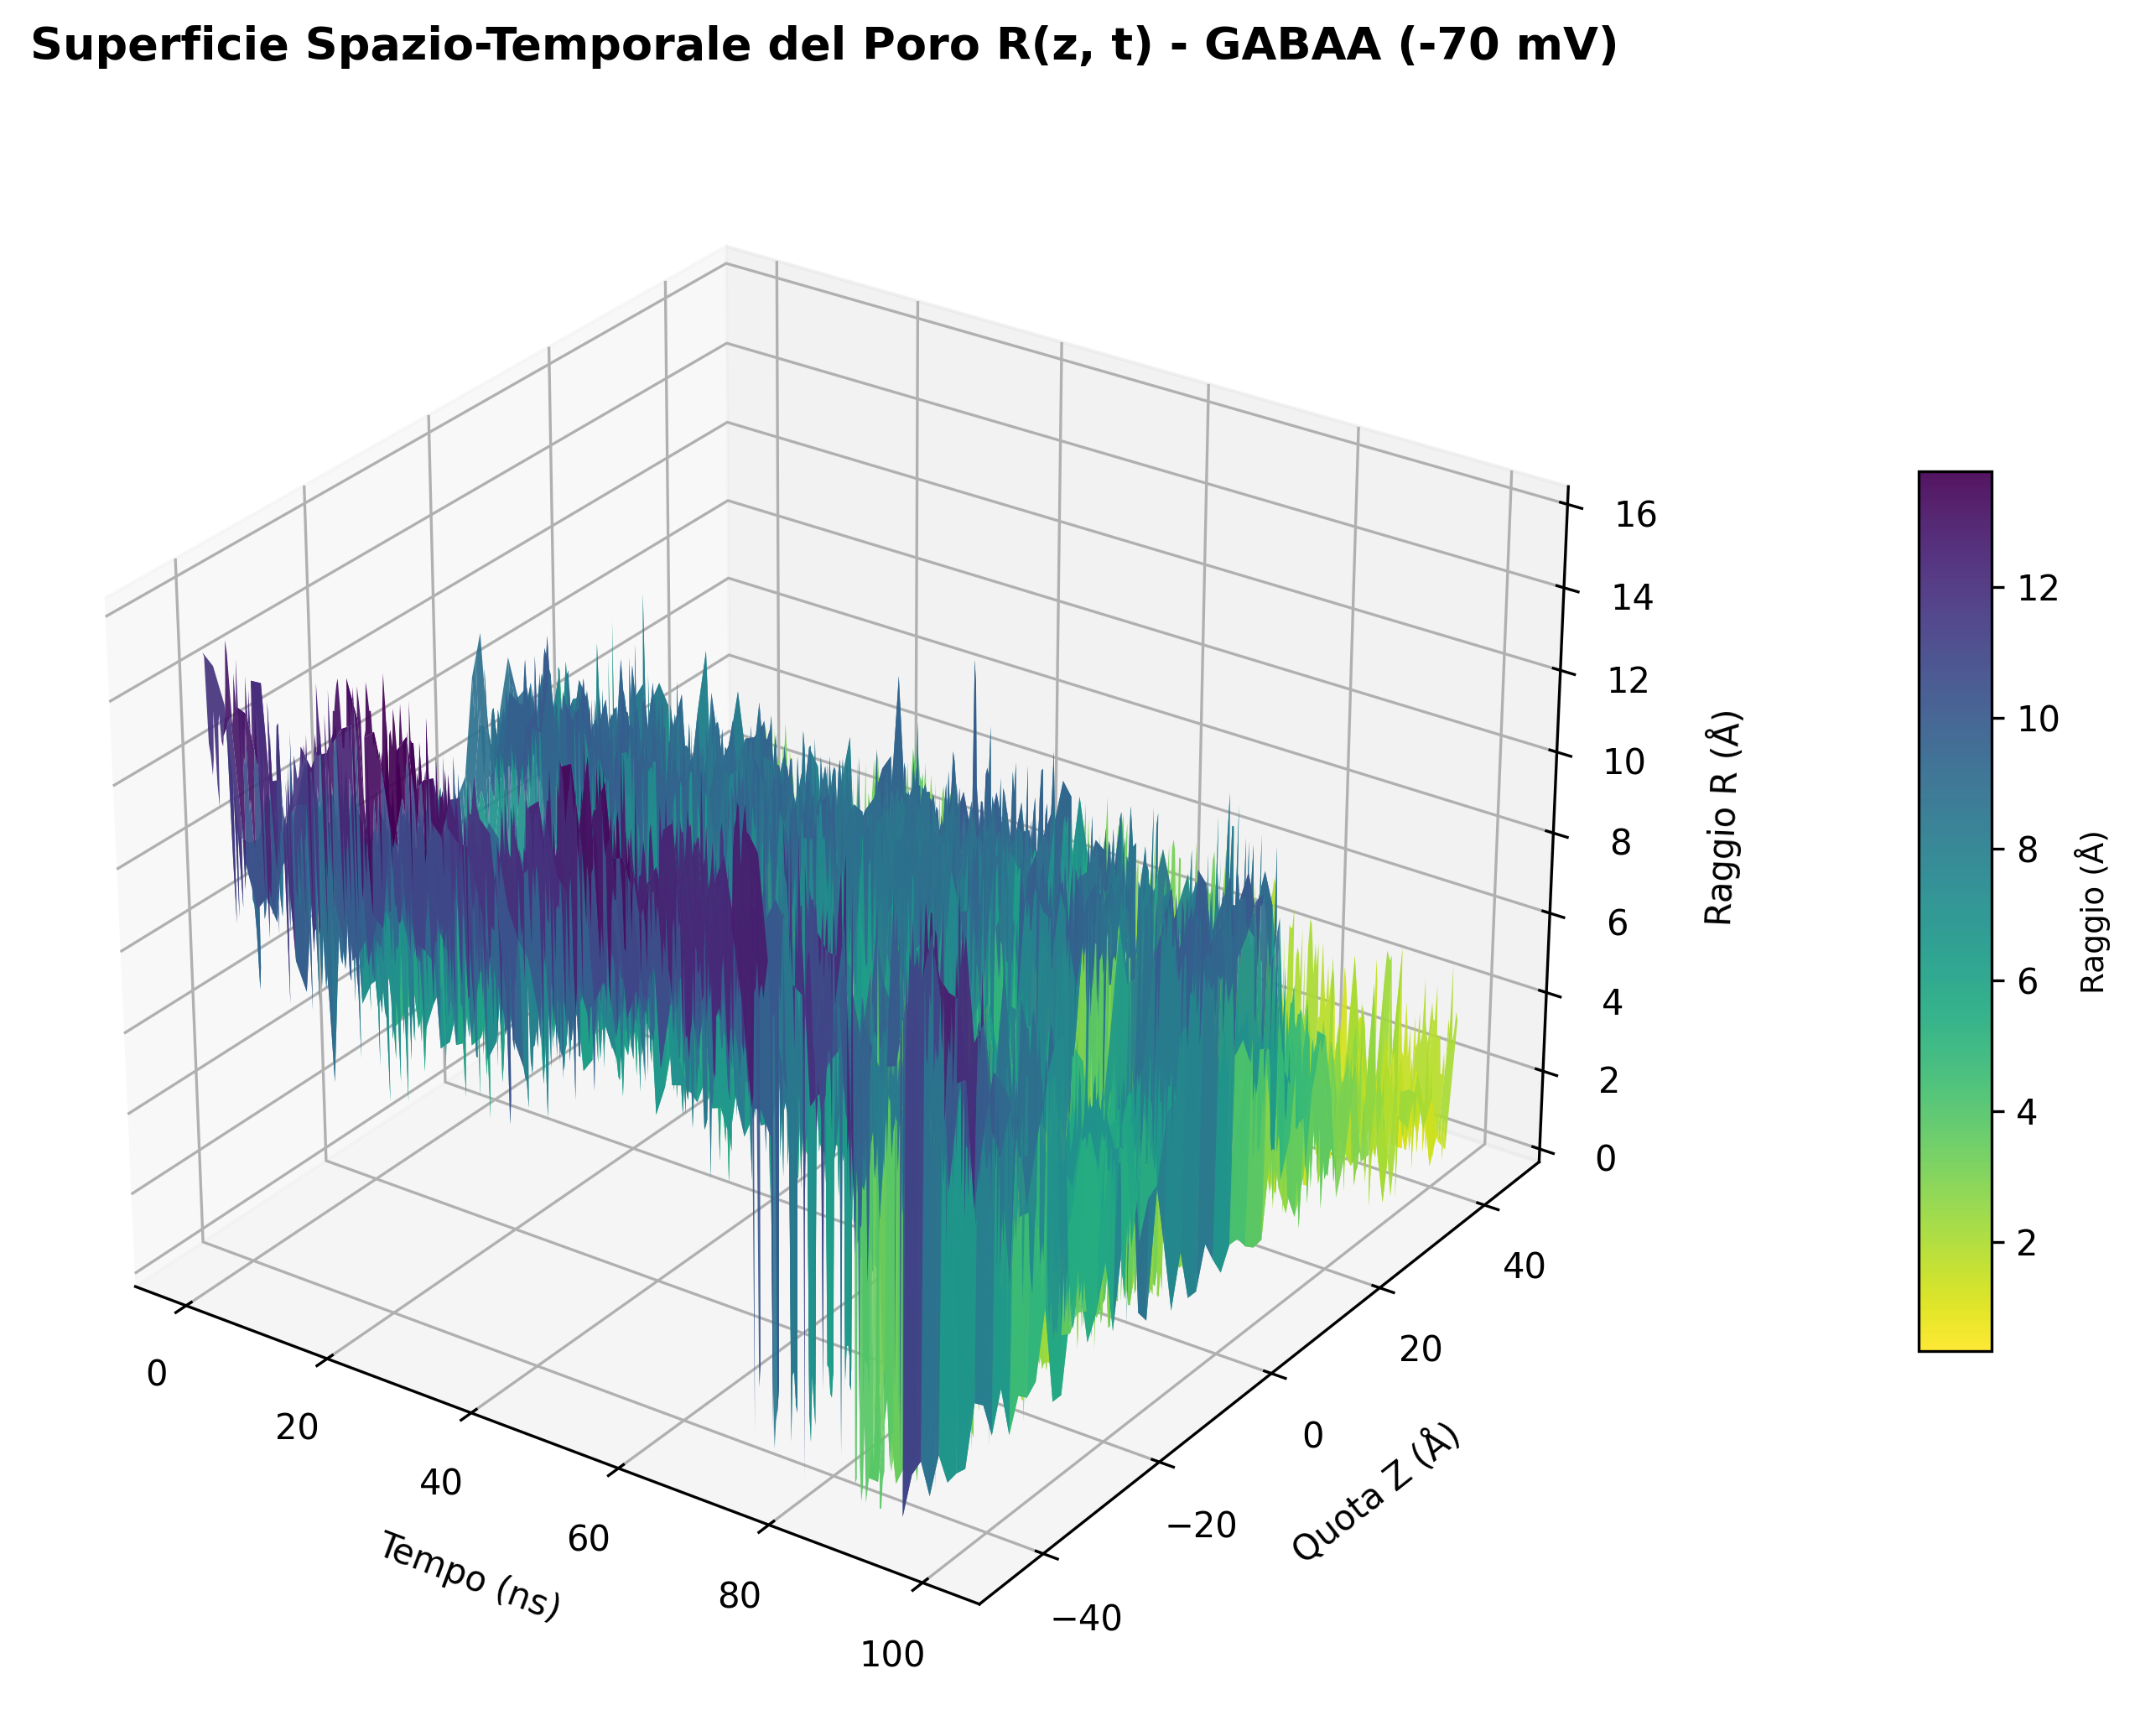

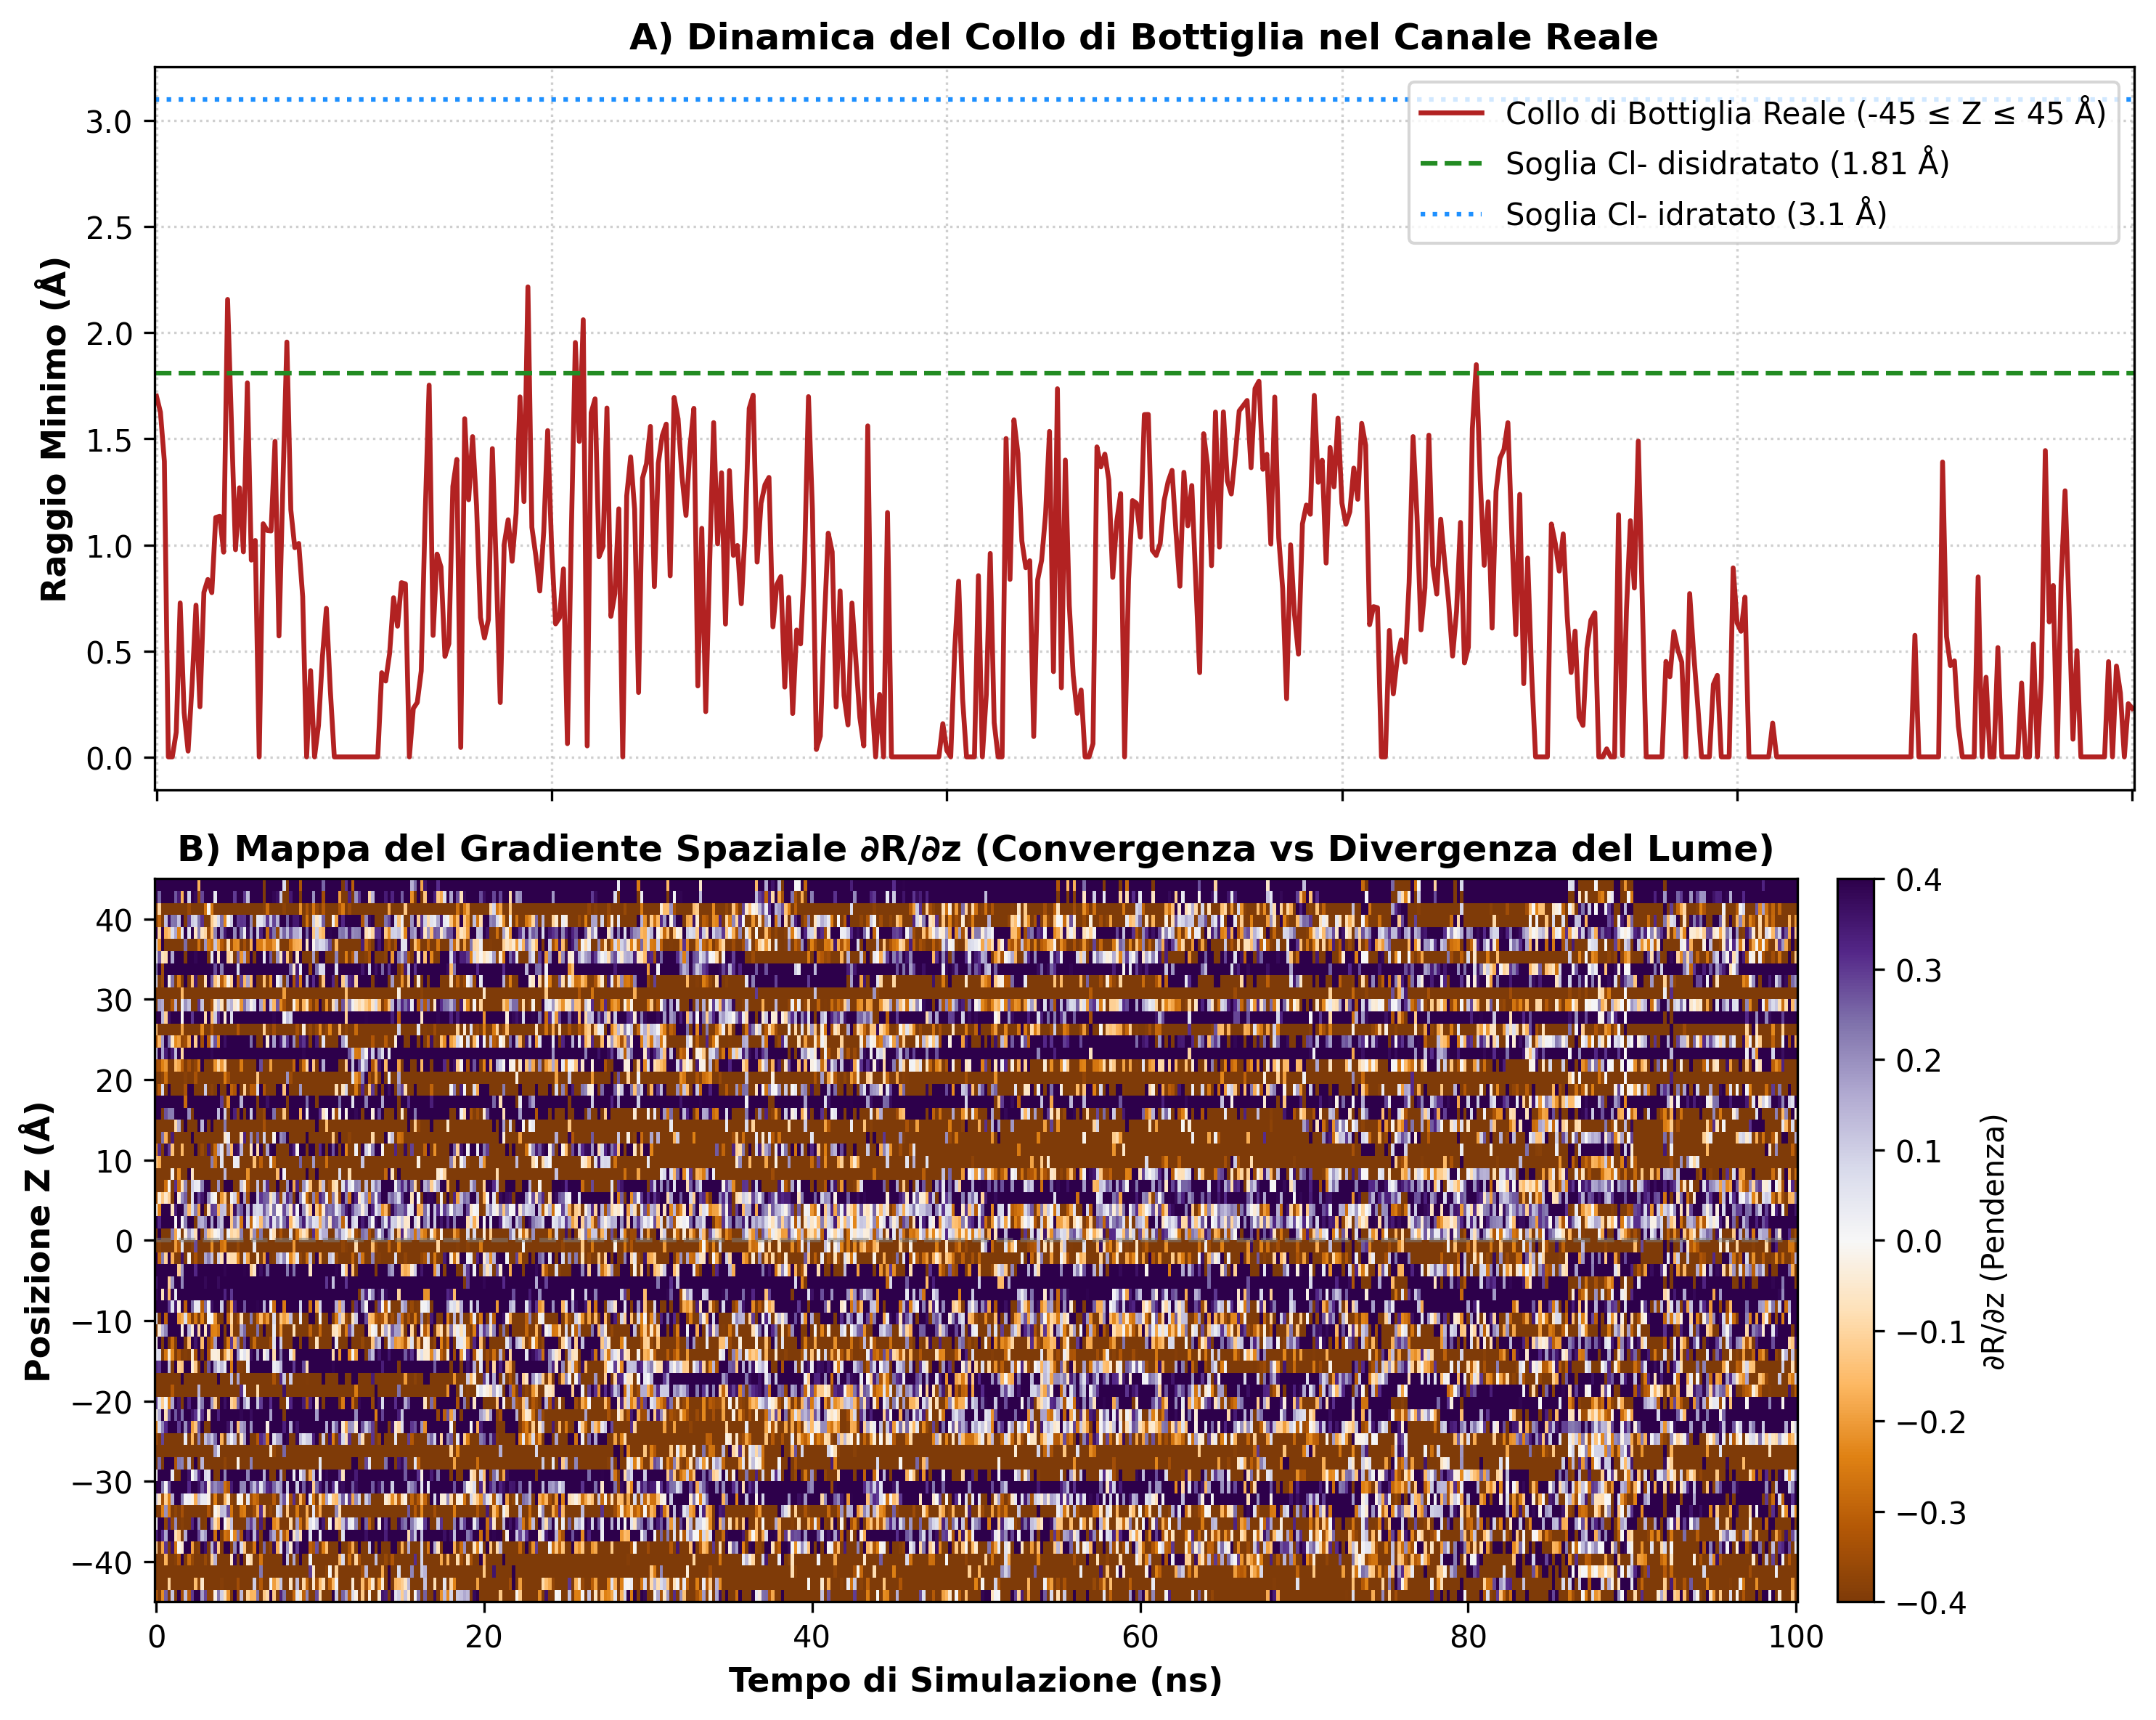

Collo di bottiglia medio nel lume reale: 0.67 ± 0.58 Å
Minimo assoluto registrato: 0.00 Å


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Carica la matrice salvata
data = np.load("matrice_poro_zt.npz")
R_matrix = data["R_matrix"]      # shape: (n_frames, n_z)
time = data["time"]              # ns
z_bins = data["z_bins"]          # Å

# Filtriamo l'intervallo reale del canale per escludere il vuoto agli estremi
mask_z = (z_bins >= -45) & (z_bins <= 45)
z_pore = z_bins[mask_z]
R_pore = R_matrix[:, mask_z]

# 1. Calcolo delle Derivate Numeriche (Gradienti)
# dR_dt: velocità di deformazione (Å/ns)
# dR_dz: pendenza geometrica del condotto (adimensionale)
dt = np.diff(time)[0]
dz = np.diff(z_pore)[0]

dR_dt, dR_dz = np.gradient(R_pore, dt, dz)

# 2. Rendering 3D Surface (stile Derive / Calc 3)
T_mesh, Z_mesh = np.meshgrid(time, z_pore, indexing='ij')

fig = plt.figure(figsize=(12, 7), dpi=300)
ax = fig.add_subplot(111, projection='3d')

# Superficie tridimensionale
surf = ax.plot_surface(T_mesh, Z_mesh, R_pore, cmap='viridis_r',
                       edgecolor='none', alpha=0.92, antialiased=True)

# Impostazione assi e punto di vista
ax.set_title("Superficie Spazio-Temporale del Poro R(z, t) - GABAA (-70 mV)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Tempo (ns)", fontsize=10, labelpad=8)
ax.set_ylabel("Quota Z (Å)", fontsize=10, labelpad=8)
ax.set_zlabel("Raggio R (Å)", fontsize=10, labelpad=8)
ax.view_init(elev=28, azim=-55)

cbar = fig.colorbar(surf, ax=ax, shrink=0.55, aspect=12, pad=0.1)
cbar.set_label("Raggio (Å)", fontsize=9)

plt.tight_layout()
plt.savefig("superficie_poro_3d.png", dpi=300)
plt.show()

# 3. Grafico del Collo di Bottiglia Reale e Mappa della Pendenza Geometrica
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=300, sharex=True)

# Collo di bottiglia filtrato (-45 <= Z <= 45)
real_bottleneck = np.min(R_pore, axis=1)
ax1.plot(time, real_bottleneck, color="firebrick", lw=1.6, label="Collo di Bottiglia Reale (-45 ≤ Z ≤ 45 Å)")
ax1.axhline(1.81, color="forestgreen", ls="--", label="Soglia Cl- disidratato (1.81 Å)")
ax1.axhline(3.1, color="dodgerblue", ls=":", label="Soglia Cl- idratato (3.1 Å)")
ax1.set_ylabel("Raggio Minimo (Å)", fontsize=11, fontweight='bold')
ax1.set_title("A) Dinamica del Collo di Bottiglia nel Canale Reale", fontsize=12, fontweight='bold')
ax1.grid(True, ls=":", alpha=0.6)
ax1.legend(loc="upper right", frameon=True)

# Mappa della pendenza dR/dz (Punti di strozzatura: dR/dz = 0)
im_grad = ax2.pcolormesh(time, z_pore, dR_dz.T, cmap="PuOr", shading="auto", vmin=-0.4, vmax=0.4)
cbar_g = fig.colorbar(im_grad, ax=ax2, pad=0.02)
cbar_g.set_label("∂R/∂z (Pendenza)", fontsize=10)
ax2.axhline(0, color="gray", ls="--", alpha=0.5)
ax2.set_xlabel("Tempo di Simulazione (ns)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Posizione Z (Å)", fontsize=11, fontweight='bold')
ax2.set_title("B) Mappa del Gradiente Spaziale ∂R/∂z (Convergenza vs Divergenza del Lume)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig("analisi_derivata_bottleneck.png", dpi=300)
plt.show()

print(f"Collo di bottiglia medio nel lume reale: {np.mean(real_bottleneck):.2f} ± {np.std(real_bottleneck):.2f} Å")
print(f"Minimo assoluto registrato: {np.min(real_bottleneck):.2f} Å")

In [ ]:
import numpy as np

# Ricarica matrice se serve
data = np.load("matrice_poro_zt.npz")
R_matrix = data["R_matrix"]
time = data["time"]
z_bins = data["z_bins"]

mask_z = (z_bins >= -45) & (z_bins <= 45)
z_pore = z_bins[mask_z]
R_pore = R_matrix[:, mask_z]

# Vettore del bottleneck per ciascun frame
bottleneck = np.min(R_pore, axis=1)

# Trova il massimo assoluto del collo di bottiglia (momento di massima apertura)
max_idx = np.argmax(bottleneck)
max_raggio = bottleneck[max_idx]
tempo_max = time[max_idx]

# Trova a quale quota Z si trovava il collo di bottiglia in quell'istante
z_idx = np.argmin(R_pore[max_idx, :])
quota_z_bottleneck = z_pore[z_idx]

print("=== STATISTICA DI MASSIMA APERTURA (BOTTLENECK PEAK) ===")
print(f"Massimo Raggio Minimo: {max_raggio:.2f} Å")
print(f"Registrato al tempo:  {tempo_max:.2f} ns (Frame {max_idx*10})")
print(f"Posizione lungo Z:     {quota_z_bottleneck:.2f} Å")

# Quanti frame superano la soglia di conduzione del Cl- disidratato (1.81 Å)?
open_frames = np.sum(bottleneck >= 1.81)
pct_open = (open_frames / len(bottleneck)) * 100
print(f"\nTempo totale con raggio >= 1.81 Å (pervio a Cl- disidratato): {pct_open:.1f}% della traiettoria ({open_frames * 0.2:.1f} ns)")

=== STATISTICA DI MASSIMA APERTURA (BOTTLENECK PEAK) ===
Massimo Raggio Minimo: 2.22 Å
Registrato al tempo:  18.80 ns (Frame 940)
Posizione lungo Z:     17.25 Å

Tempo totale con raggio >= 1.81 Å (pervio a Cl- disidratato): 1.2% della traiettoria (1.2 ns)


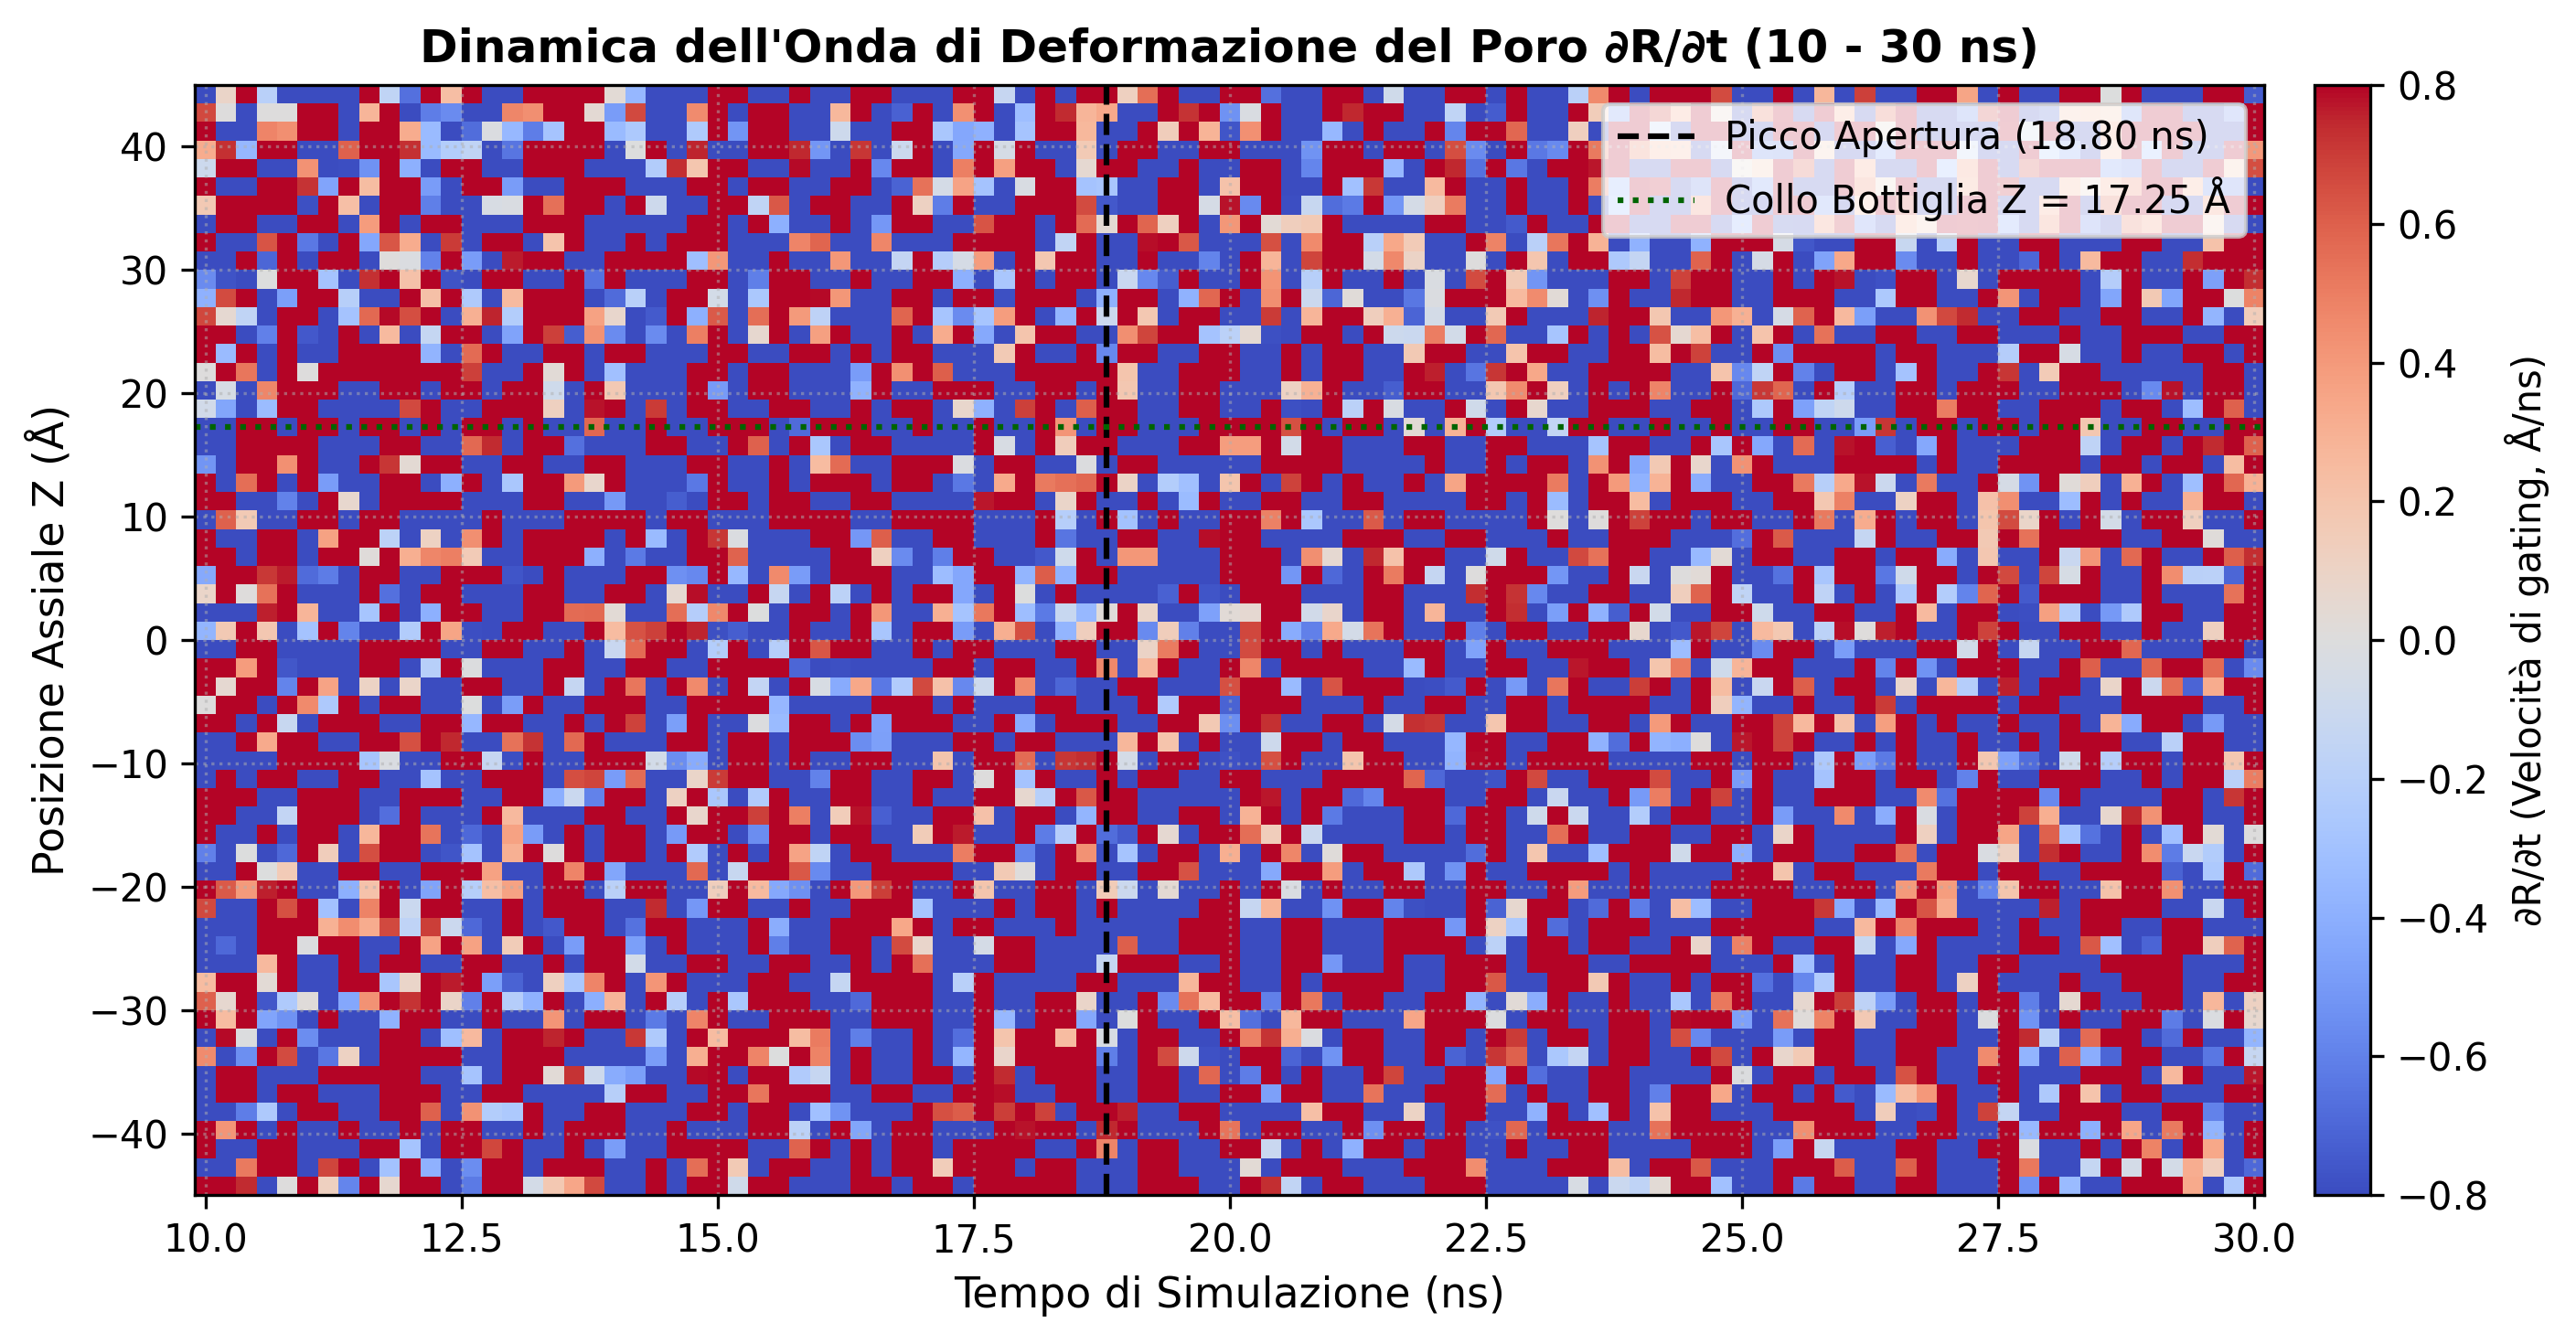

Velocità massima di espansione: +15.56 Å/ns
Velocità massima di contrazione: -18.69 Å/ns


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Carica la matrice (se non già in memoria)
data = np.load("matrice_poro_zt.npz")
R_matrix = data["R_matrix"]
time = data["time"]
z_bins = data["z_bins"]

mask_z = (z_bins >= -45) & (z_bins <= 45)
z_pore = z_bins[mask_z]
R_pore = R_matrix[:, mask_z]

# Calcolo differenziale: velocità locale dR/dt (Å/ns)
dt = np.diff(time)[0]
dR_dt = np.gradient(R_pore, dt, axis=0)

# Mappa della velocità di espansione/contrazione (zoom 10-30 ns)
mask_t = (time >= 10) & (time <= 30)
time_zoom = time[mask_t]
dR_dt_zoom = dR_dt[mask_t, :]

plt.figure(figsize=(10, 5), dpi=300)
# Rosso = espansione rapida (dilatazione), Blu = contrazione rapida (restringimento)
im = plt.pcolormesh(time_zoom, z_pore, dR_dt_zoom.T, cmap="coolwarm", shading="auto", vmin=-0.8, vmax=0.8)
cbar = plt.colorbar(im, pad=0.02)
cbar.set_label("∂R/∂t (Velocità di gating, Å/ns)", fontsize=10)

plt.axvline(18.80, color="black", linestyle="--", lw=1.5, label="Picco Apertura (18.80 ns)")
plt.axhline(17.25, color="darkgreen", linestyle=":", lw=1.5, label="Collo Bottiglia Z = 17.25 Å")

plt.title("Dinamica dell'Onda di Deformazione del Poro ∂R/∂t (10 - 30 ns)", fontsize=12, fontweight='bold')
plt.xlabel("Tempo di Simulazione (ns)", fontsize=11)
plt.ylabel("Posizione Assiale Z (Å)", fontsize=11)
plt.legend(loc="upper right", frameon=True)
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig("velocita_gating_onda.png", dpi=300)
plt.show()

max_speed_exp = np.max(dR_dt_zoom)
max_speed_con = np.min(dR_dt_zoom)
print(f"Velocità massima di espansione: +{max_speed_exp:.2f} Å/ns")
print(f"Velocità massima di contrazione: {max_speed_con:.2f} Å/ns")

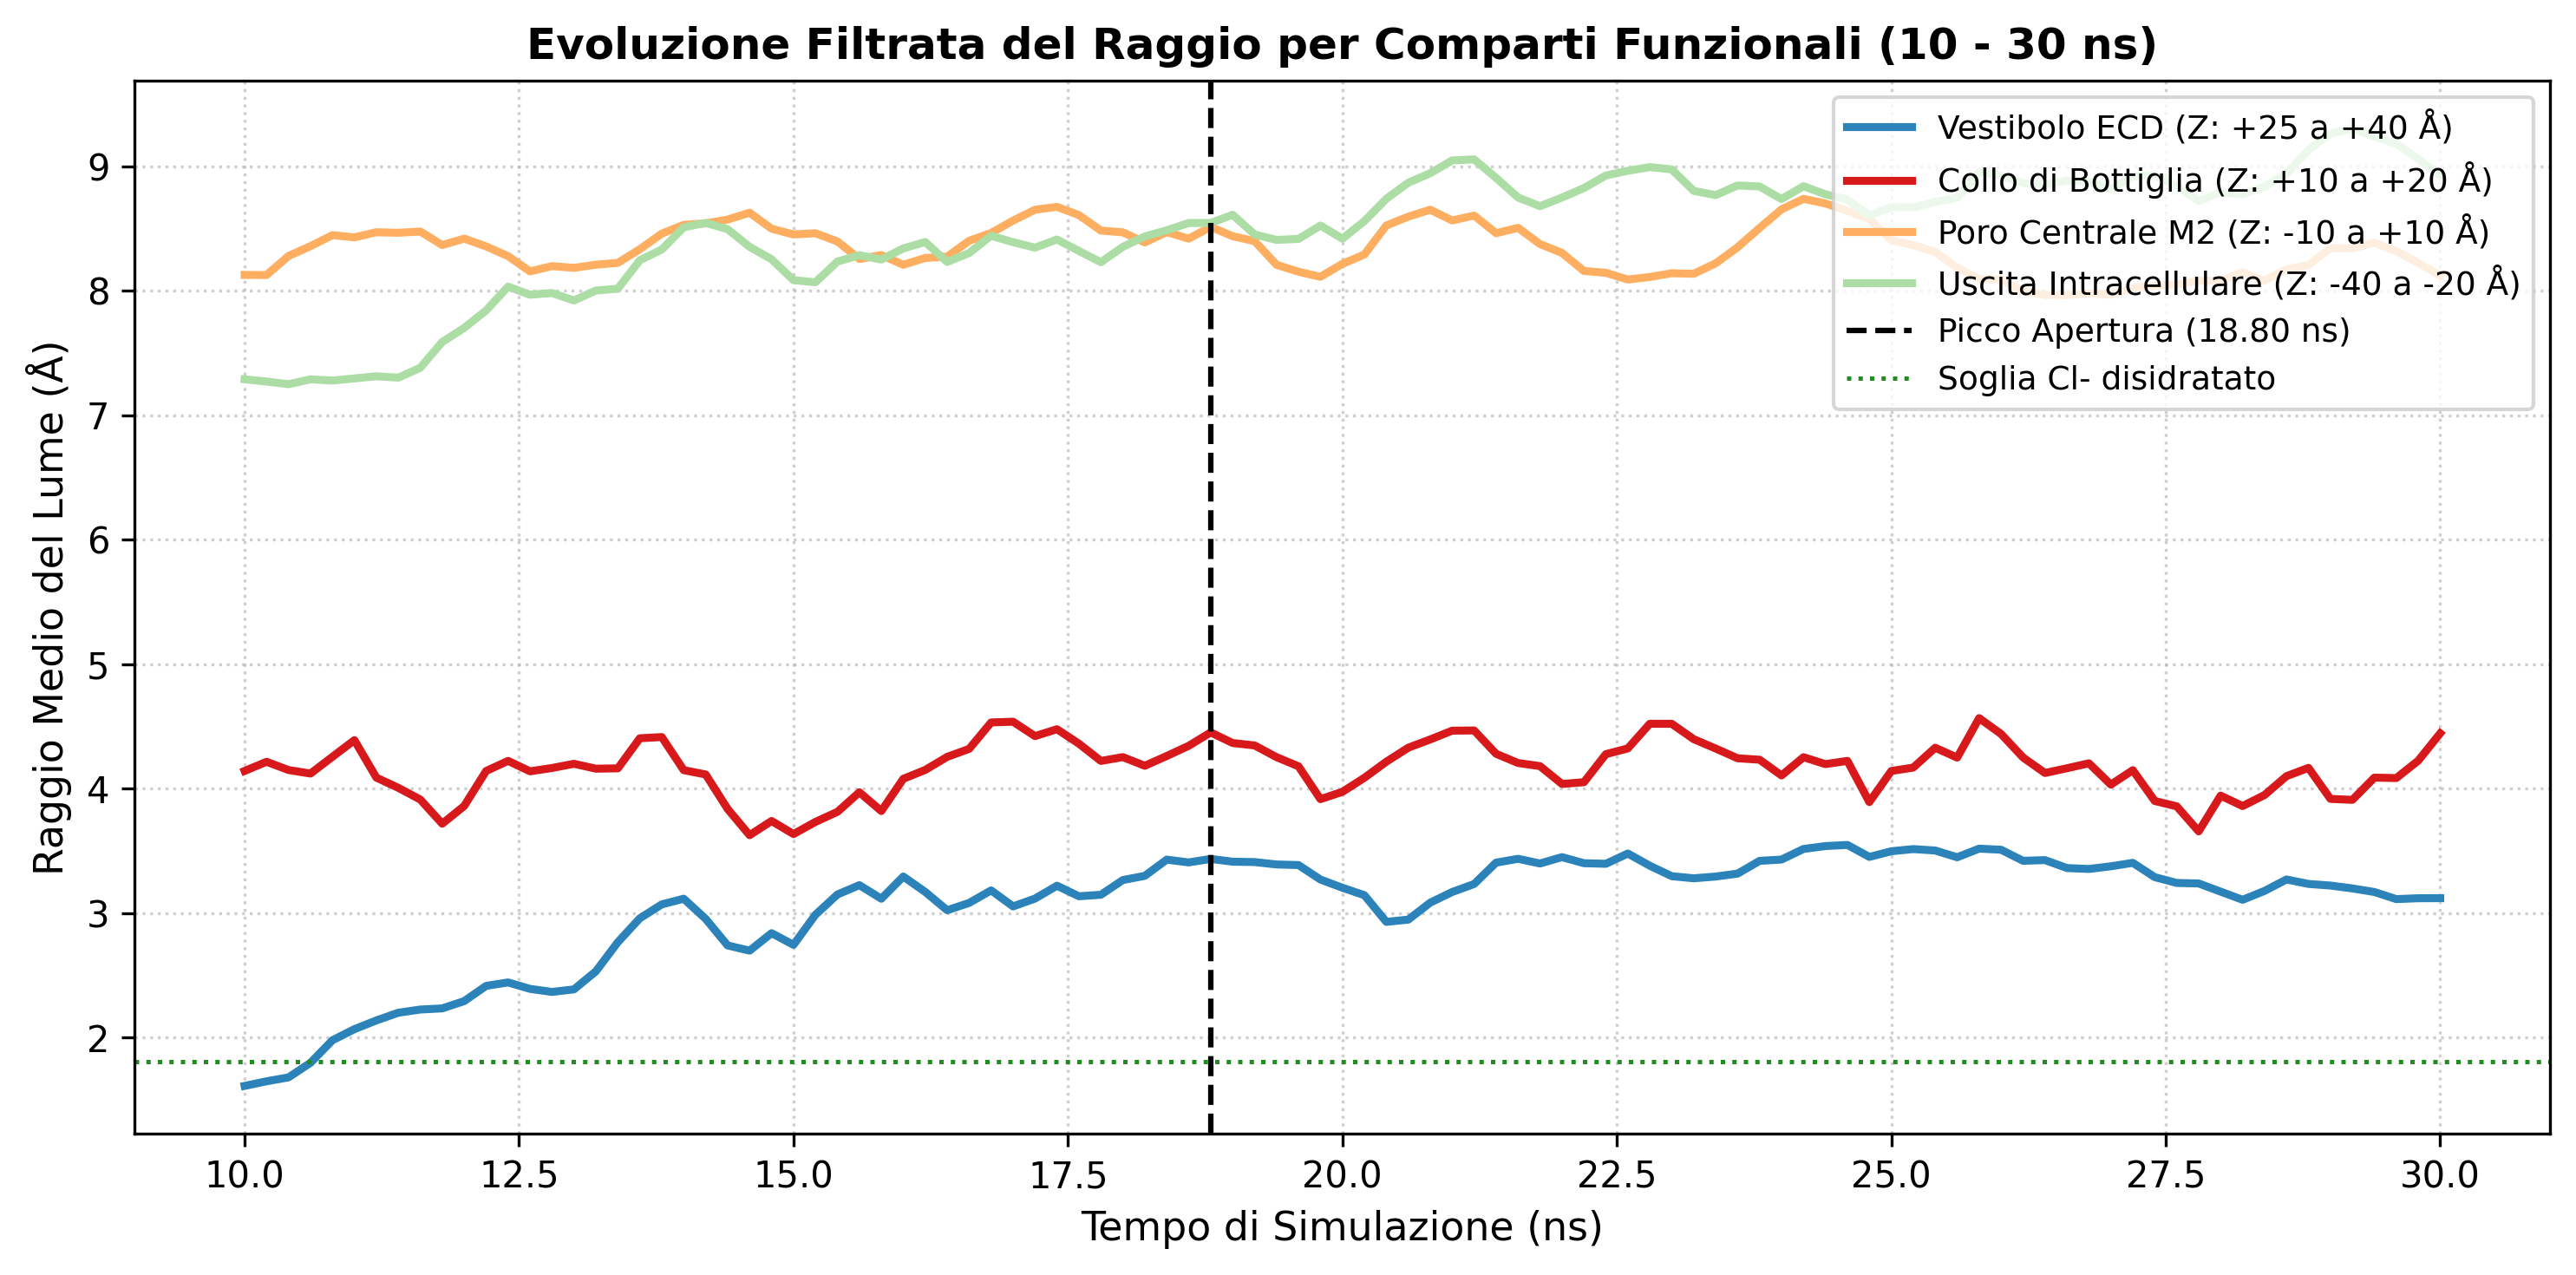

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

# Caricamento matrice se necessario
data = np.load("matrice_poro_zt.npz")
R_matrix = data["R_matrix"]
time = data["time"]
z_bins = data["z_bins"]

# Definizione macro-zone lungo Z
zones = {
    "Vestibolo ECD (Z: +25 a +40 Å)": (z_bins >= 25) & (z_bins <= 40),
    "Collo di Bottiglia (Z: +10 a +20 Å)": (z_bins >= 10) & (z_bins <= 20),
    "Poro Centrale M2 (Z: -10 a +10 Å)": (z_bins >= -10) & (z_bins <= 10),
    "Uscita Intracellulare (Z: -40 a -20 Å)": (z_bins >= -40) & (z_bins <= -20)
}

# Zoom nella finestra critica 10-30 ns
mask_t = (time >= 10) & (time <= 30)
t_zoom = time[mask_t]

plt.figure(figsize=(10, 5), dpi=300)

colors = ["#2b83ba", "#d7191c", "#fdae61", "#abdda4"]

for (name, z_mask), col in zip(zones.items(), colors):
    # Raggio medio della zona
    r_zone = np.mean(R_matrix[:, z_mask], axis=1)
    r_zone_zoom = r_zone[mask_t]
    # Smussamento del rumore termico (finestra a media mobile di ~1 ns)
    r_smooth = uniform_filter1d(r_zone_zoom, size=5)
    plt.plot(t_zoom, r_smooth, label=name, color=col, lw=2.2)

plt.axvline(18.80, color="black", linestyle="--", lw=1.5, label="Picco Apertura (18.80 ns)")
plt.axhline(1.81, color="forestgreen", linestyle=":", lw=1.2, label="Soglia Cl- disidratato")

plt.title("Evoluzione Filtrata del Raggio per Comparti Funzionali (10 - 30 ns)", fontsize=12, fontweight='bold')
plt.xlabel("Tempo di Simulazione (ns)", fontsize=11)
plt.ylabel("Raggio Medio del Lume (Å)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(frameon=True, fontsize=9, loc="upper right")
plt.tight_layout()
plt.savefig("evoluzione_zone_poro.png", dpi=300)
plt.show()

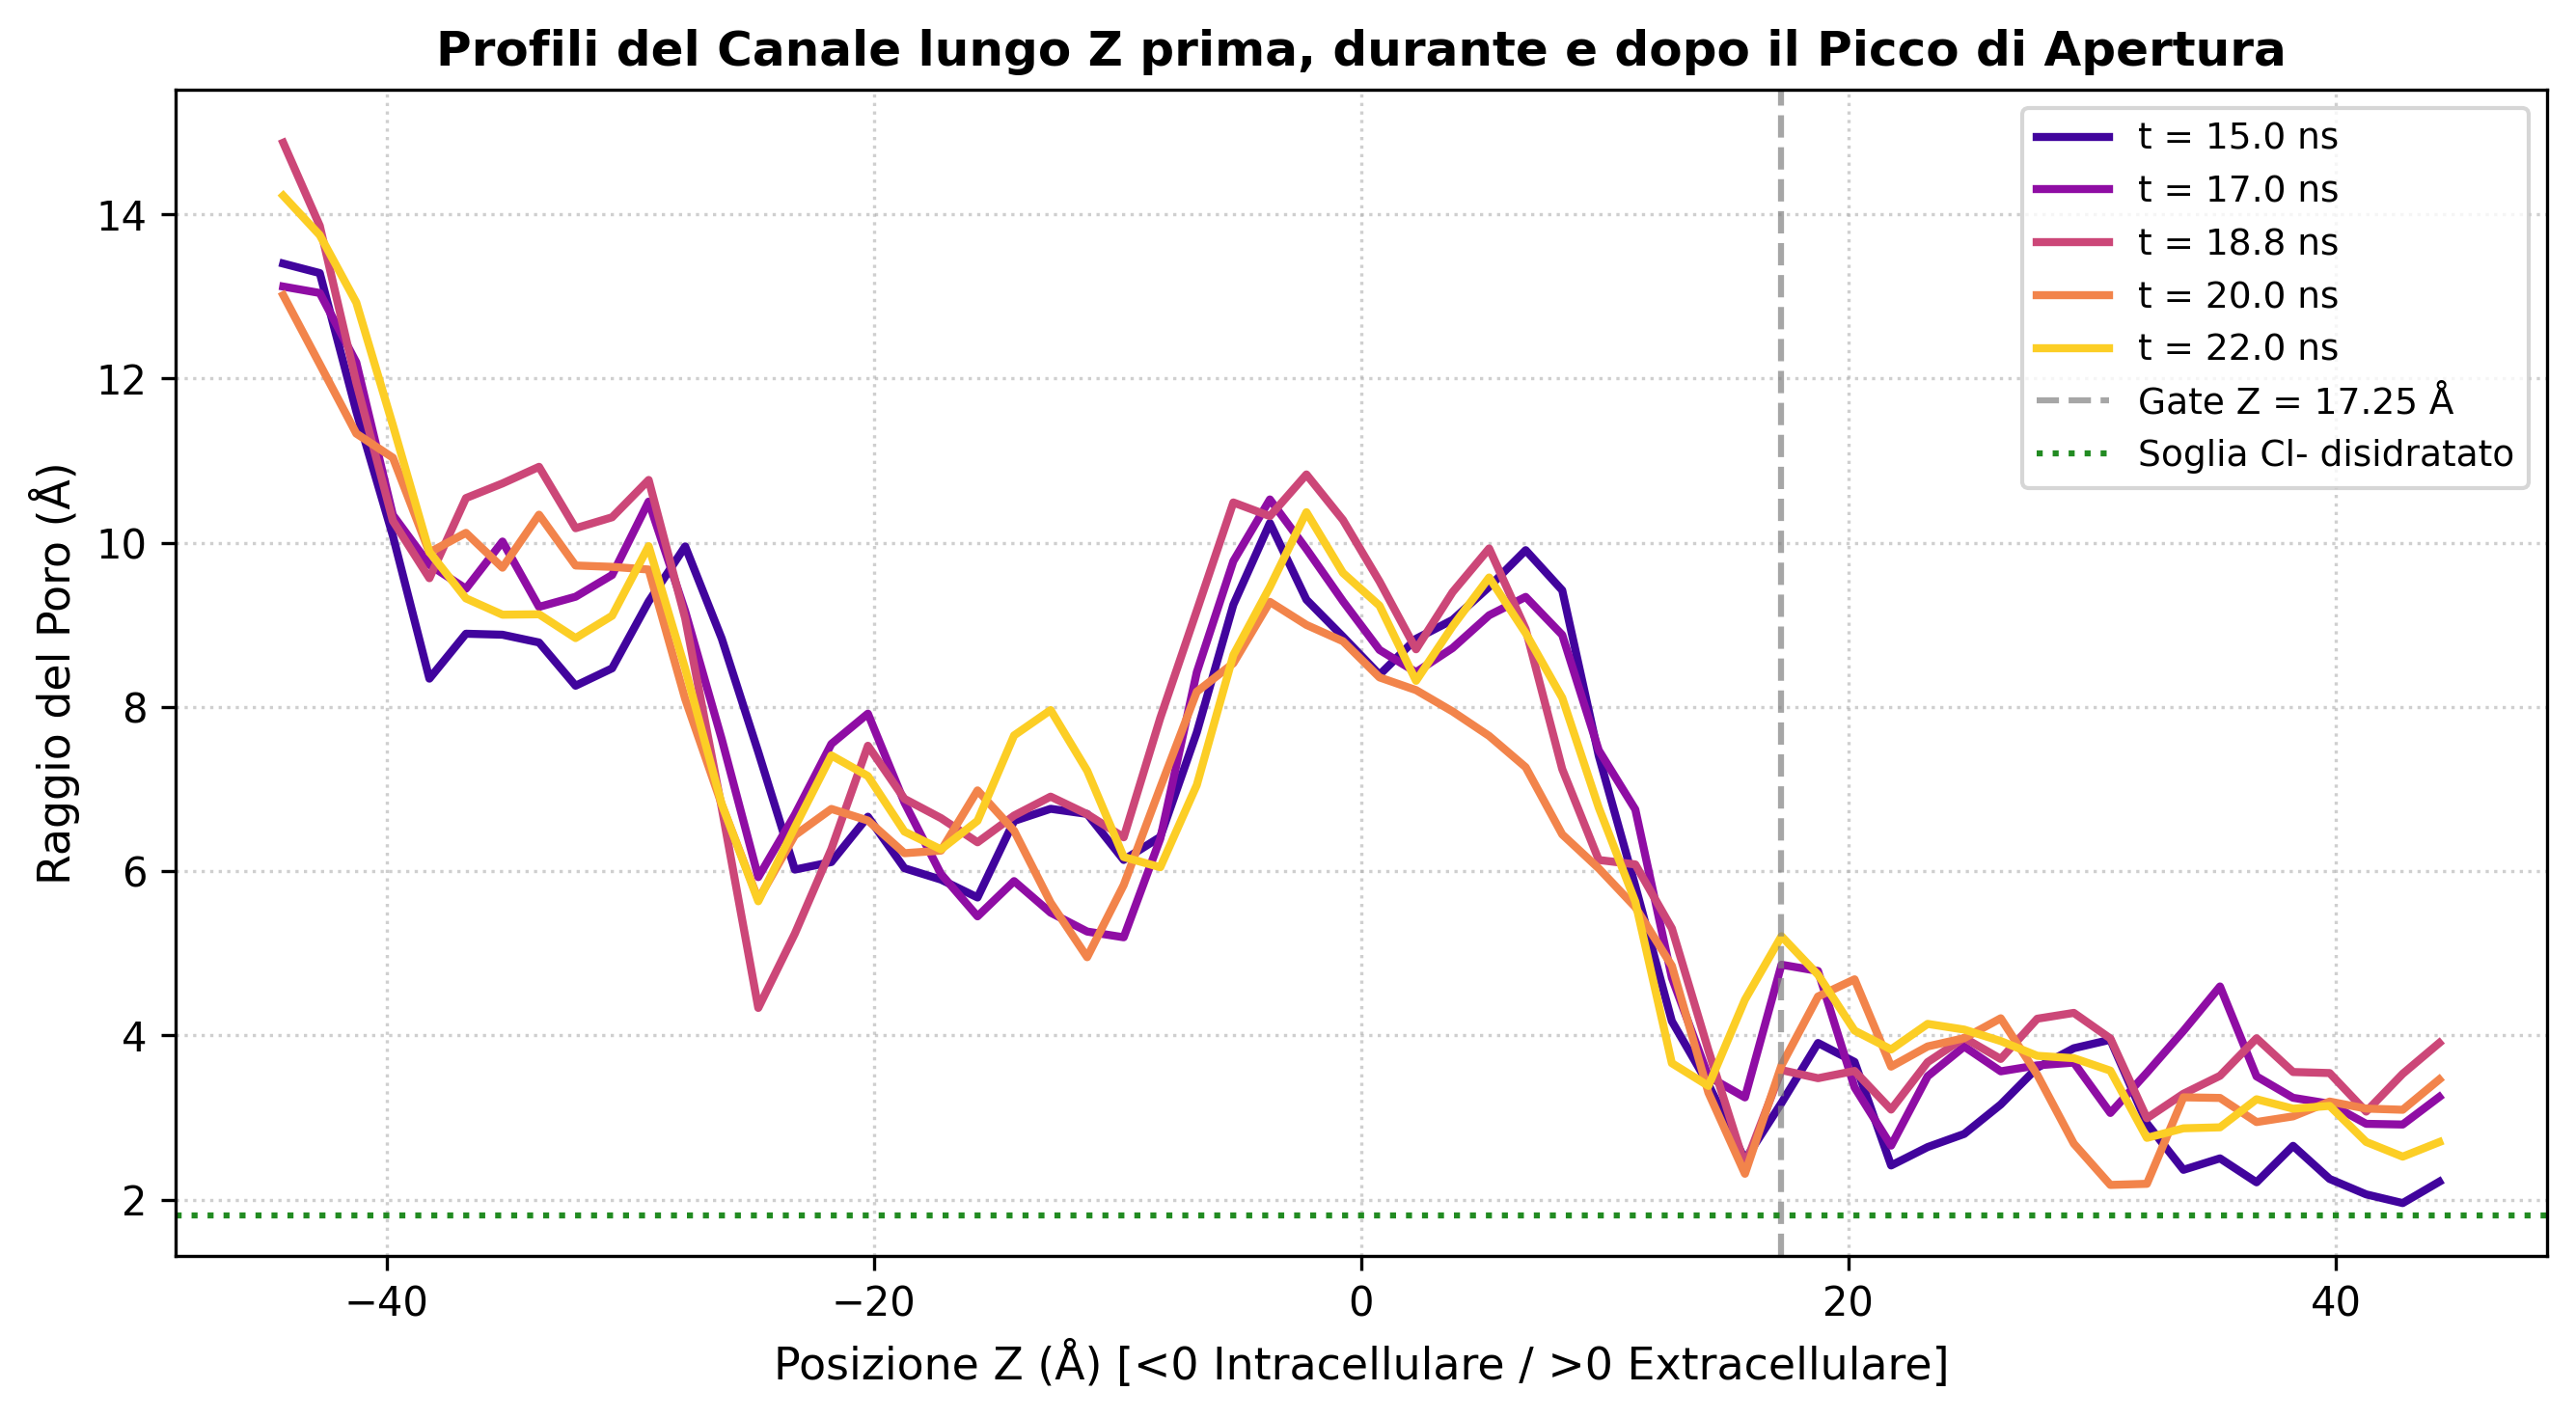

In [8]:
snapshot_times = [15.0, 17.0, 18.8, 20.0, 22.0]
mask_z = (z_bins >= -45) & (z_bins <= 45)

plt.figure(figsize=(9, 5), dpi=300)

palette = plt.cm.plasma(np.linspace(0.1, 0.9, len(snapshot_times)))

for target_t, color in zip(snapshot_times, palette):
    f_idx = np.argmin(np.abs(time - target_t))
    profile = R_matrix[f_idx, mask_z]
    # Smussamento spaziale lungo Z per evidenziare la forma
    profile_smooth = uniform_filter1d(profile, size=3)
    plt.plot(z_bins[mask_z], profile_smooth, label=f"t = {time[f_idx]:.1f} ns", color=color, lw=2.0)

plt.axvline(17.25, color="gray", linestyle="--", alpha=0.7, label="Gate Z = 17.25 Å")
plt.axhline(1.81, color="forestgreen", linestyle=":", label="Soglia Cl- disidratato")

plt.title("Profili del Canale lungo Z prima, durante e dopo il Picco di Apertura", fontsize=12, fontweight='bold')
plt.xlabel("Posizione Z (Å) [<0 Intracellulare / >0 Extracellulare]", fontsize=11)
plt.ylabel("Raggio del Poro (Å)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.savefig("profili_sequenziali_poro.png", dpi=300)
plt.show()

Trovati 146 ioni Cl- nel sistema.
Analisi delle traiettorie individuali lungo l'asse Z...

=== RISULTATO PERMEAZIONE IONICA (100 ns) ===
Eventi di permeazione completa (Full translocation): 138
Eventi di ingresso parziale nel poro:                0


/tmp/ipykernel_5471/4227573250.py:88: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


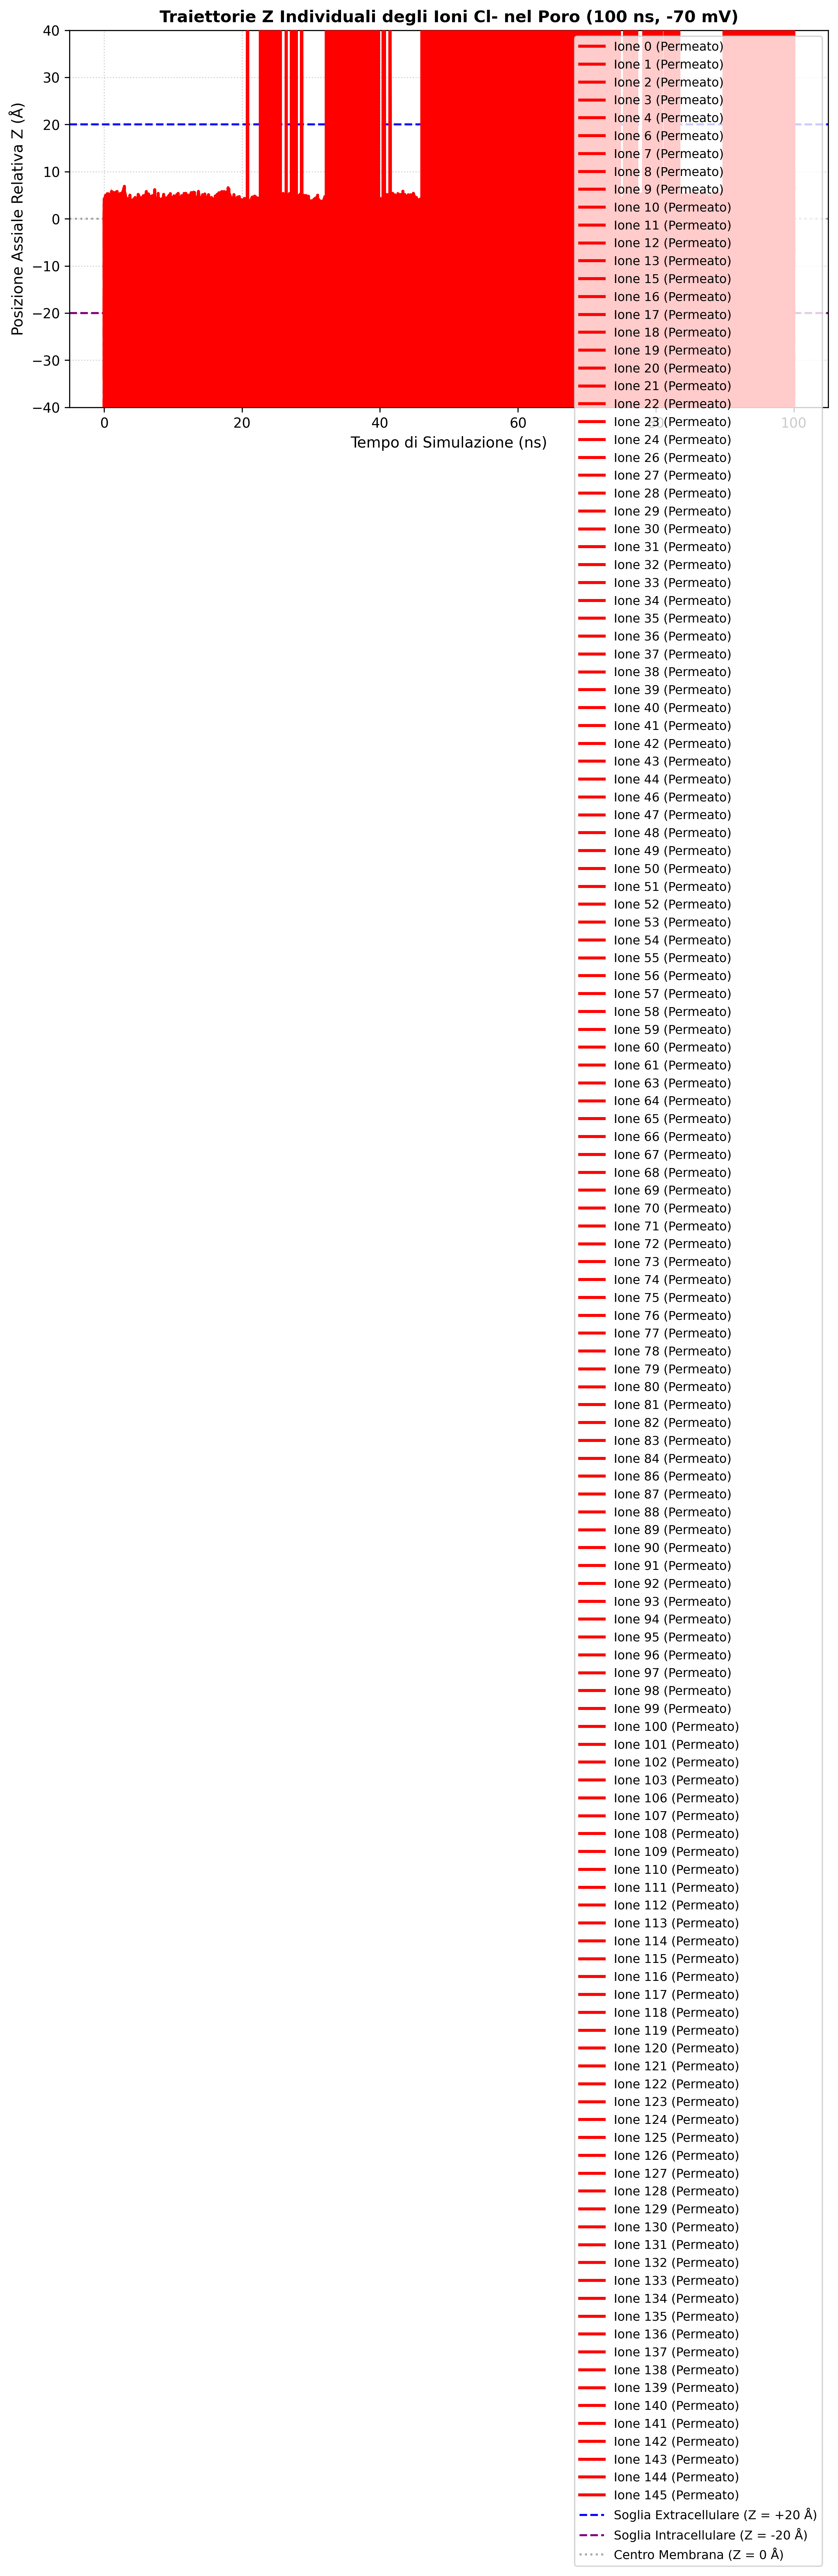

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Selezioni
sel_prot = u.select_atoms("protein")
ions_cl = u.select_atoms("resname CLA or resname CL")
n_ions = len(ions_cl)

print(f"Trovati {n_ions} ioni Cl- nel sistema.")
print("Analisi delle traiettorie individuali lungo l'asse Z...")

# Definiamo le soglie dei comparti (in Å relativi al centro della proteina)
Z_EXTRA = 20.0   # Bocca extracellulare
Z_INTRA = -20.0  # Uscita intracellulare
R_MAX_PORE = 15.0 # Raggio radiale massimo per considerare lo ione 'nel poro'

# Matrice delle posizioni Z per ciascuno ione Cl- nel tempo
n_frames = len(u.trajectory)
times_ns = np.zeros(n_frames)
z_trajectories = np.zeros((n_frames, n_ions))
r_trajectories = np.zeros((n_frames, n_ions))

for f_idx, ts in enumerate(u.trajectory):
    times_ns[f_idx] = ts.time / 1000.0
    com_p = sel_prot.center_of_mass()

    cl_rel = ions_cl.positions - com_p
    z_trajectories[f_idx, :] = cl_rel[:, 2]
    r_trajectories[f_idx, :] = np.sqrt(cl_rel[:, 0]**2 + cl_rel[:, 1]**2)

# 2. Identificazione degli eventi di traslocazione completa
# Uno ione permea se: parte da Z >= Z_EXTRA ed entra a Z <= Z_INTRA passando attraverso il poro
translocation_events = []
partial_entries = []

for ion_idx in range(n_ions):
    z_track = z_trajectories[:, ion_idx]
    r_track = r_trajectories[:, ion_idx]

    # Verifichiamo se lo ione è entrato nel lume del canale (r < 15 Å)
    inside_pore = r_track < R_MAX_PORE

    # Evento forward: da Extra (> +20) a Intra (< -20)
    has_started_extra = np.any((z_track[:500] >= Z_EXTRA) & inside_pore[:500])
    has_reached_intra = np.any((z_track >= Z_INTRA) & (z_track <= Z_INTRA + 5) & inside_pore)

    # Controlliamo il passaggio continuo
    min_z = np.min(z_track[inside_pore]) if np.any(inside_pore) else 999
    max_z = np.max(z_track[inside_pore]) if np.any(inside_pore) else -999

    if min_z <= Z_INTRA and max_z >= Z_EXTRA:
        translocation_events.append(ion_idx)
    elif min_z < 0 and max_z >= Z_EXTRA:
        partial_entries.append(ion_idx)

print("\n" + "="*45)
print("=== RISULTATO PERMEAZIONE IONICA (100 ns) ===")
print(f"Eventi di permeazione completa (Full translocation): {len(translocation_events)}")
print(f"Eventi di ingresso parziale nel poro:                {len(partial_entries)}")
print("="*45)

# 3. Visualizzazione grafica delle traiettorie
plt.figure(figsize=(10, 5), dpi=300)

# Traccia tutti gli ioni che hanno almeno sfiorato il poro
plotted_count = 0
for ion_idx in range(n_ions):
    r_track = r_trajectories[:, ion_idx]
    z_track = z_trajectories[:, ion_idx]

    if np.any(r_track < 12.0):  # ioni che sono entrati nel poro
        if ion_idx in translocation_events:
            plt.plot(times_ns, z_track, lw=2.2, color="red", label=f"Ione {ion_idx} (Permeato)", zorder=5)
        else:
            plt.plot(times_ns, z_track, lw=0.8, alpha=0.45)
            plotted_count += 1

plt.axhline(Z_EXTRA, color="blue", ls="--", label="Soglia Extracellulare (Z = +20 Å)")
plt.axhline(Z_INTRA, color="purple", ls="--", label="Soglia Intracellulare (Z = -20 Å)")
plt.axhline(0, color="gray", ls=":", alpha=0.7, label="Centro Membrana (Z = 0 Å)")

plt.title("Traiettorie Z Individuali degli Ioni Cl- nel Poro (100 ns, -70 mV)", fontsize=12, fontweight='bold')
plt.xlabel("Tempo di Simulazione (ns)", fontsize=11)
plt.ylabel("Posizione Assiale Relativa Z (Å)", fontsize=11)
plt.ylim(-40, 40)
plt.grid(True, ls=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True, fontsize=9)
plt.tight_layout()
plt.savefig("traiettorie_cloruro_permeazione.png", dpi=300)
plt.show()

=== VERIFICA RIGOROSA DELLA CONDUTTANZA ===
Ioni Cl- che hanno esplorato il Gate (Z=14-20 Å, R ≤ 5 Å): 9
Ioni che hanno completato la traslocazione oltre Z=0:      0


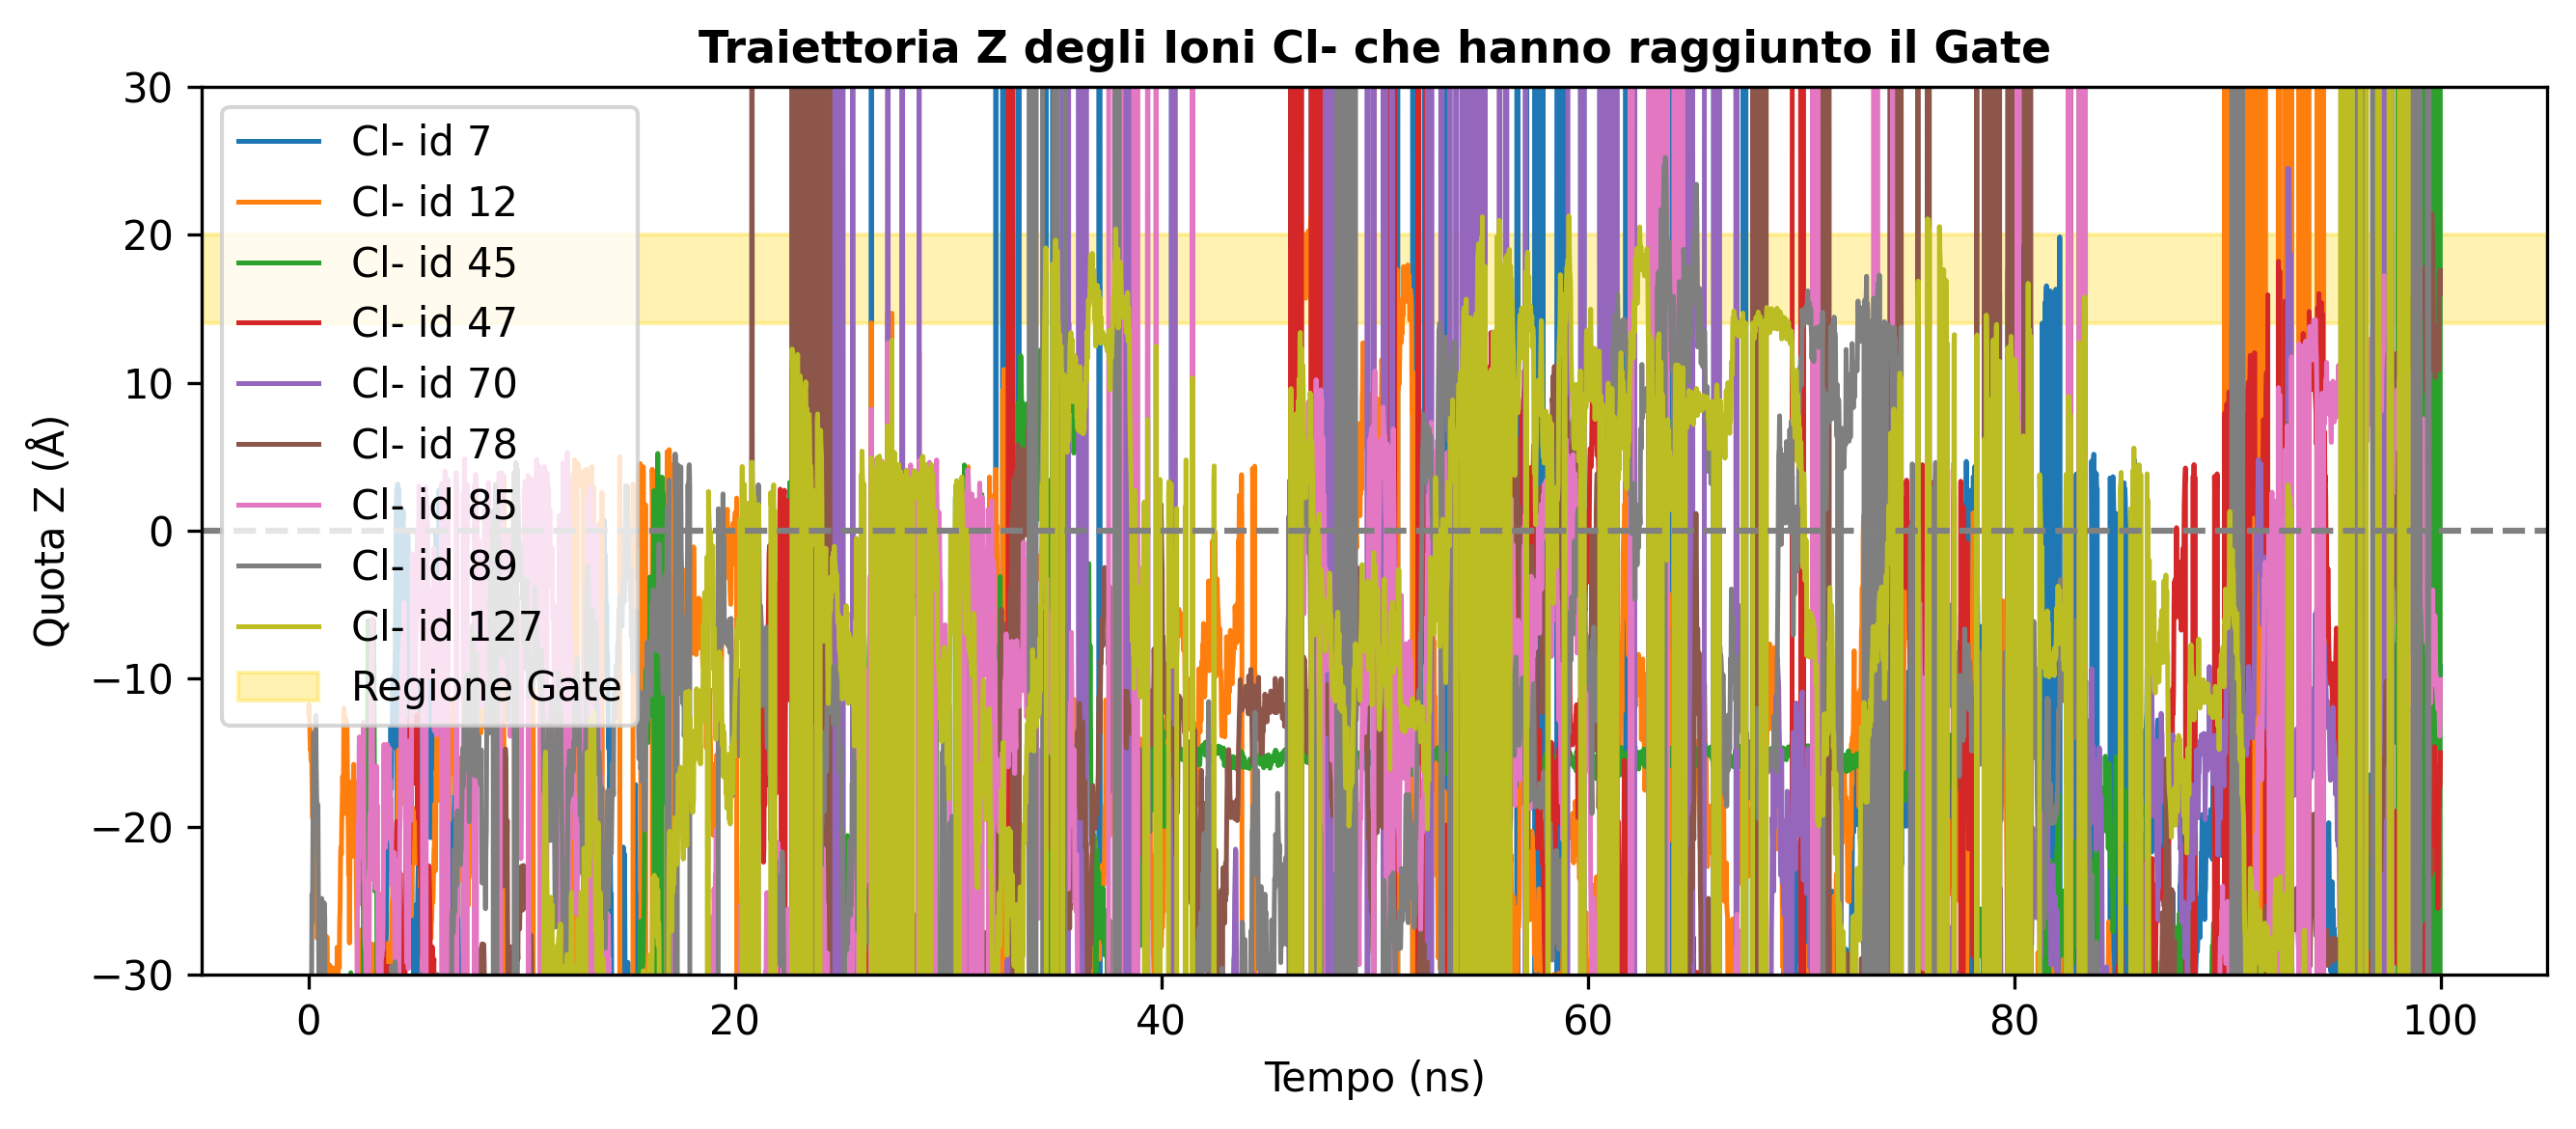

In [10]:
import numpy as np
import matplotlib.pyplot as plt

sel_prot = u.select_atoms("protein")
ions_cl = u.select_atoms("resname CLA or resname CL")
n_ions = len(ions_cl)

# Soglie geometriche del vero lume
R_STRICT_LUMEN = 5.0  # Angstrom dal centro assiale (raggio interno del lume)
Z_GATE_MIN = 14.0
Z_GATE_MAX = 20.0

ions_visiting_gate = []
permeated_true = []

for ion_idx in range(n_ions):
    r_track = r_trajectories[:, ion_idx]
    z_track = z_trajectories[:, ion_idx]

    # Ha mai visitato il gate all'interno del lume stretto?
    in_gate = (z_track >= Z_GATE_MIN) & (z_track <= Z_GATE_MAX) & (r_track <= R_STRICT_LUMEN)

    if np.any(in_gate):
        ions_visiting_gate.append(ion_idx)

        # Verifichiamo se ha proseguito verso il basso attraversando Z=0 restando nel lume
        times_in_gate = np.where(in_gate)[0]
        t_first = times_in_gate[0]

        # Traiettoria successiva all'ingresso nel gate
        subsequent_z = z_track[t_first:]
        subsequent_r = r_track[t_first:]

        # Ha raggiunto Z < 0 rimanendo nel raggio del canale (senza salti PBC > 10 Å/frame)?
        steps_down = (subsequent_z < 0) & (subsequent_r < 8.0)
        max_jump = np.max(np.abs(np.diff(subsequent_z))) if len(subsequent_z) > 1 else 0

        if np.any(steps_down) and max_jump < 10.0:
            permeated_true.append(ion_idx)

print("=== VERIFICA RIGOROSA DELLA CONDUTTANZA ===")
print(f"Ioni Cl- che hanno esplorato il Gate (Z=14-20 Å, R ≤ 5 Å): {len(ions_visiting_gate)}")
print(f"Ioni che hanno completato la traslocazione oltre Z=0:      {len(permeated_true)}")

if len(ions_visiting_gate) > 0:
    plt.figure(figsize=(9, 4), dpi=300)
    for idx in ions_visiting_gate:
        plt.plot(times_ns, z_trajectories[:, idx], lw=1.2, label=f"Cl- id {idx}")
    plt.axhspan(Z_GATE_MIN, Z_GATE_MAX, color="gold", alpha=0.3, label="Regione Gate")
    plt.axhline(0, color="gray", ls="--")
    plt.title("Traiettoria Z degli Ioni Cl- che hanno raggiunto il Gate", fontsize=11, fontweight='bold')
    plt.xlabel("Tempo (ns)")
    plt.ylabel("Quota Z (Å)")
    plt.ylim(-30, 30)
    plt.legend()
    plt.tight_layout()
    plt.show()